# Código Paulina – Libro de trabajo de grado (Huila, AlphaEarth y Tessera)

**Es el libro de Felipe (`codigo_principal`) con la misma numeración (1 a 10) y sus celdas originales.** Solo se cambió lo necesario para seguir las indicaciones del profesor (modelo **binario** Bosque / No bosque, tres fuentes de etiquetas, 70/30, RF/SVM/XGBoost). Un solo libro con todos los pasos.

| Paso | Origen | Cambio |
|---|---|---|
| 1, 1.1 | Felipe | 1.1: cambia el nombre del archivo exportado para no pisar el de Felipe. Se agrega una celda de preparación (`RUTA`, `df`, `EXT`, `KW`) que el cuaderno de Felipe daba por definida |
| 2, 3 | Felipe | Sin cambios |
| 4 | Felipe | Tu proyecto de Earth Engine; se omite si ya existen los `.tif` de ESA |
| 5, 8 | Felipe | Solo el proyecto de Earth Engine (ya tienen "saltar si existe") |
| 6 | Felipe + **6B nuevo** | 6A (6 clases) se conserva; 6B = tabla binaria con ESA, Dynamic World e IDEAM |
| 7 | Felipe + **7B nuevo** | 7A (6 clases) se conserva; 7B = binario, 70/30 por bloques, RF/SVM/XGBoost |
| 9 | Felipe, **adaptado** | Usa el modelo binario de 7B y guarda en `modelos_paulina` |
| 10 | Felipe, **adaptado** | Misma máscara, sobre las inferencias binarias |

**Cuidado:** 6A y 7A escriben en las carpetas de Felipe (`datos/entrenamiento`, `modelos`). Para el modelo binario basta con ejecutar 6B, 7B, 9 y 10; las variables de 6B/7B terminan en `_P` o tienen carpeta propia (`datos/binario_paulina`, `modelos_paulina`) para no chocar.

# 1 Montar Google Drive

In [1]:
#Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')
#

Mounted at /content/drive


### Preparación (nueva)
**Qué hace:** define `ROOT`, `RUTA`, `EXT`, `KW`, `fmt` y la tabla `df` de archivos que los pasos 2 y 3 del cuaderno de Felipe usan sin definirlos (venían de una celda anterior que no está en su libro).

**Cómo funciona el código:** crea las rutas, los diccionarios que describen extensiones y palabras clave, y lista todos los archivos de `datos/paulina` en una tabla.

In [ ]:
import os, pandas as pd
ROOT = '/content/drive/MyDrive/APLICACIONES SIG'
GEE_PROJECT = 'tesis-503417'          # CAMBIAR por tu proyecto de Earth Engine
RUTA = f'{ROOT}/DATOS'
EXT = {'.shp':'Vector','.dbf':'Atributos','.prj':'Proyección','.shx':'Índice','.cpg':'Codificación','.tif':'Ráster GeoTIFF','.xml':'Metadatos','.adf':'Ráster ArcInfo'}
KW  = {'drenaje':'hidrografía','embalse':'embalse','vias':'vías','dem':'modelo digital de elevación','construcciones':'construcciones','cobertura':'cobertura de la tierra (CORINE)'}
fmt = lambda b: f'{b/1e9:.2f} GB' if b >= 1e9 else f'{b/1e6:.1f} MB' if b >= 1e6 else f'{b/1e3:.0f} KB'
df = pd.DataFrame({'Archivo': [os.path.relpath(os.path.join(d, f), RUTA) for d, _, fs_ in os.walk(RUTA) for f in fs_]})
print(len(df), 'archivos en', RUTA)

919 archivos en /content/drive/MyDrive/APLICACIONES SIG/DATOS


## 1.1 Extraer todo el código y outputs
**Qué hace:** (Felipe) guarda en un `.txt` todo el código y las salidas del cuaderno, más el árbol de carpetas del proyecto, para compartir el estado del trabajo.

**Qué cambió:** solo `NOMBRE`, para no sobrescribir el archivo de Felipe.

**Cómo funciona el código, por partes:** (1) pide a Colab el contenido del cuaderno y lo recorre celda por celda, quitando colores y recortando salidas largas; (2) `arbol()` dibuja el árbol de carpetas con tamaños; (3) guarda el archivo en `exportes_notebooks`.

In [ ]:
# ===== PANEL DE CONTROL =====
RAIZ = "/content/drive/MyDrive/APLICACIONES SIG"
CARPETA = "exportes_notebooks"            # se crea si no existe
NOMBRE = "notebook_paulina_codigo_outputs_y_estructura.txt"
MAX_CHARS_OUTPUT = 5000                   # None = sin límite por output
MAX_ARCHIVOS_POR_CARPETA = 10             # None = listar todos
PROFUNDIDAD_MAX = None                    # None = sin límite
MOSTRAR_TAMANO = True
SOBREESCRIBIR = True

# ===== CÓDIGO =====
import os, re
from google.colab import drive, _message
drive.mount("/content/drive")

# --- 1. Código y outputs ---
nb = _message.blocking_request("get_ipynb", timeout_sec=60)["ipynb"]
txt = lambda x: "".join(x) if isinstance(x, list) else str(x)
ansi = re.compile(r"\x1b\[[0-9;]*m")

partes = ["#" * 80 + "\n# CÓDIGO Y OUTPUTS DEL NOTEBOOK\n" + "#" * 80]
for i, c in enumerate(nb["cells"], 1):
    partes.append(f"\n{'='*80}\n[{i}] {c['cell_type'].upper()}\n{'='*80}\n{txt(c['source'])}")
    for o in c.get("outputs", []):
        t = o["output_type"]
        if t == "stream":  s = txt(o["text"])
        elif t == "error": s = "\n".join(o.get("traceback", [f"{o['ename']}: {o['evalue']}"]))
        else:              s = txt(o.get("data", {}).get("text/plain", "[output no textual]"))
        s = ansi.sub("", s)
        if MAX_CHARS_OUTPUT and len(s) > MAX_CHARS_OUTPUT:
            s = s[:MAX_CHARS_OUTPUT] + "\n...[truncado]"
        partes.append(f"\n--- OUTPUT ({t}) ---\n{s}")

# --- 2. Estructura de carpetas ---
def tam(b):
    for u in ["B", "KB", "MB", "GB"]:
        if b < 1024: return f"{b:.0f} {u}"
        b /= 1024
    return f"{b:.1f} TB"

def arbol(ruta, pref="", nivel=0):
    if PROFUNDIDAD_MAX is not None and nivel >= PROFUNDIDAD_MAX: return []
    try: items = list(os.scandir(ruta))
    except PermissionError: return [pref + "└── [sin acceso]"]
    dirs = sorted([e for e in items if e.is_dir()], key=lambda e: e.name.lower())
    archs = sorted([e for e in items if e.is_file()], key=lambda e: e.name.lower())
    extra = 0
    if MAX_ARCHIVOS_POR_CARPETA is not None and len(archs) > MAX_ARCHIVOS_POR_CARPETA:
        extra, archs = len(archs) - MAX_ARCHIVOS_POR_CARPETA, archs[:MAX_ARCHIVOS_POR_CARPETA]
    entradas = dirs + archs + (["__extra__"] if extra else [])
    out = []
    for k, e in enumerate(entradas):
        ult = k == len(entradas) - 1
        rama, sig = ("└── ", "    ") if ult else ("├── ", "│   ")
        if e == "__extra__":
            out.append(f"{pref}{rama}... (+{extra} archivos más)")
        elif e.is_dir():
            out.append(f"{pref}{rama}{e.name}/")
            out += arbol(e.path, pref + sig, nivel + 1)
        else:
            out.append(f"{pref}{rama}{e.name}" + (f"  [{tam(e.stat().st_size)}]" if MOSTRAR_TAMANO else ""))
    return out

partes.append("\n\n" + "#" * 80 + "\n# ESTRUCTURA DE LA CARPETA RAÍZ\n" + "#" * 80)
partes.append("\n" + os.path.basename(RAIZ) + "/\n" + "\n".join(arbol(RAIZ)))

# --- 3. Guardar ---
ruta = os.path.join(RAIZ, CARPETA, NOMBRE)
os.makedirs(os.path.dirname(ruta), exist_ok=True)
if os.path.exists(ruta) and not SOBREESCRIBIR:
    print("Ya existe, no se sobrescribe:", ruta)
else:
    with open(ruta, "w", encoding="utf-8") as f: f.write("".join(partes))
    print(f"✅ {len(nb['cells'])} celdas + árbol de carpetas → {ruta}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ 46 celdas + árbol de carpetas → /content/drive/MyDrive/APLICACIONES SIG/exportes_notebooks/notebook_paulina_codigo_outputs_y_estructura.txt


# 2 Explorar archivos geoespaciales del Huila para el proyecto (carpeta paulina)

**Qué hace:** (Felipe) lista las capas de `datos/paulina` (hidrografía, vías, DEM, inventario forestal del IDEAM…) con su tamaño y una descripción inferida por el nombre. Sirve para confirmar que están los archivos del IDEAM (`SMBYC`, `CBBQ`) que se usan como etiquetas en 6B.

**Cómo funciona el código, por partes:** completa los diccionarios `EXT` y `KW`, agrupa los archivos por capa (un `.shp` con su `.dbf` y `.prj` es una capa) y muestra la tabla.

In [ ]:
import re
EXT.update({'.sbn':'Índice espacial','.sbx':'Índice espacial','.ovr':'Pirámides ráster','.lyr':'Estilo ArcGIS'})
KW.update({'smbyc':'IDEAM-SMByC','cbbq':'bosque/no bosque','dccb':'cambio cobertura bosque',
           'inventario':'inventario forestal','aoi':'área de estudio','giff':'GeoTIFF'})

df['Capa'] = df['Archivo'].str.replace(r'(\.tif)?(\.aux\.xml|\.vat\.\w+|\.\w+)$', '', regex=True)
df['bytes'] = [os.path.getsize(os.path.join(RUTA, a)) for a in df['Archivo']]
g = df.groupby('Capa').agg(ext=('Archivo', lambda s: ' '.join(sorted({os.path.splitext(x)[1] for x in s}))),
                           bytes=('bytes', 'sum')).reset_index()
g['Descripción inferida'] = [', '.join(sorted({v for k, v in KW.items() if k in c.lower()})) or 'tema no evidente' for c in g['Capa']]
g['Archivo'] = g['Capa'] + '  [' + g['ext'] + ']'
g['Tamaño'] = g['bytes'].apply(fmt)
pd.set_option('display.max_rows', None)
display(g[['Archivo', 'Descripción inferida', 'Tamaño']])

,Archivo,Descripción inferida,Tamaño
0,AOI_Huila/AOI_Huila [.cpg .dbf .prj .sbn .sbx...,área de estudio,266 KB
1,AOI_Huila/AOI_Huila.shp [.xml],área de estudio,10 KB
2,CONSTRUCCIONES/CONSTRUCCION [.cpg .dbf .prj ....,construcciones,13.8 MB
3,CONSTRUCCIONES/CONSTRUCCION.shp [.xml],construcciones,25 KB
4,CONSTRUCCIONES_P/construcciones_p [.cpg .dbf ...,construcciones,14.8 MB
5,CONSTRUCCIONES_P/construcciones_p.shp [.xml],construcciones,29 KB
6,DEM_CLIP/dem_huila [.ovr .xml],modelo digital de elevación,8.6 MB
7,DEM_CLIP/dem_huila/dblbnd [.adf],modelo digital de elevación,0 KB
8,DEM_CLIP/dem_huila/hdr [.adf],modelo digital de elevación,0 KB
9,DEM_CLIP/dem_huila/metadata [.xml],modelo digital de elevación,2 KB


# 3 Exploracion mas detalla de los datos

**Qué hace:** (Felipe) abre cada ráster del inventario forestal y cada capa vectorial de `datos/paulina` y guarda sus metadatos (sistema de coordenadas, tamaño, resolución, valor sin dato, clases con su número de píxeles).

**Para qué sirve aquí:** de ahí salen los valores del diccionario `IDEAM` de 6B (p. ej. 2018: 1 Bosque estable, 2 Deforestación, 5 No bosque estable). Produce `metadatos_totales/metadatos.json`.

**Cómo funciona el código, por partes:** `rasterio` lee los metadatos de los `.tif` (y la tabla `.vat.dbf` si existe); `pyogrio` lee los de los vectores; se guarda todo en un JSON.

In [ ]:
import json, os, glob, rasterio, pyogrio, geopandas as gpd

OUT = f'{RUTA}/metadatos_totales'; os.makedirs(OUT, exist_ok=True)
meta = {}
for t in sorted(glob.glob(f'{RUTA}/INVENTARIO FORESTAL/**/*.tif', recursive=True)):
    with rasterio.open(t) as s:
        m = dict(tipo='raster', crs=str(s.crs), ancho=s.width, alto=s.height, res=s.res, dtype=s.dtypes[0],
                 nodata=s.nodata, bounds=list(s.bounds), piramides=s.overviews(1), tamano_GB=round(os.path.getsize(t)/1e9, 2))
    if os.path.exists(t + '.vat.dbf'):
        m['clases'] = gpd.read_file(t + '.vat.dbf').drop(columns='geometry', errors='ignore').to_dict('records')
    meta[os.path.relpath(t, RUTA)] = m

for v in glob.glob(f'{RUTA}/**/*.shp', recursive=True):
    i = pyogrio.read_info(v)
    meta[os.path.relpath(v, RUTA)] = dict(tipo='vector', crs=str(i['crs']), geometria=i['geometry_type'],
                                          n_registros=int(i['features']), campos=list(i['fields']), bounds=list(i['total_bounds']))

with open(f'{OUT}/metadatos.json', 'w', encoding='utf-8') as f:
    json.dump(meta, f, ensure_ascii=False, indent=2, default=str)
print(f'{len(meta)} capas documentadas en {OUT}/metadatos.json')

12 capas documentadas en /content/drive/MyDrive/APLICACIONES SIG/DATOS/metadatos_totales/metadatos.json


# 4 Extracción de coberturas ESA al Huila (Tree, Shrubland, Grassland, Built-up, Cropland y Bare-sparse)

**Qué hace:** (Felipe) descarga de Earth Engine el mapa ESA WorldCover 2020 y 2021 recortado al Huila (10 m, seis clases).

**Qué cambió:** tu proyecto de Earth Engine y una verificación inicial: si `esa_wc_huila_2020.tif` y `_2021.tif` ya están en `datos/clases_esa` (es el caso), la celda no repite la descarga.

**Cómo funciona el código, por partes:** toma la colección ESA de cada año, la recorta al área de estudio, lanza la exportación a Drive, espera a que terminen las tareas y mueve los `.tif`.

In [ ]:
import os
_ya = all(os.path.exists(f'/content/drive/MyDrive/APLICACIONES SIG/DATOS/clases_esa/esa_wc_huila_{y}.tif') for y in (2020, 2021))
if _ya: print('⏭  Las coberturas ESA ya están en datos/clases_esa')
else:
    import ee, os, glob, shutil, time
    import geopandas as gpd

    GEE_PROJECT = GEE_PROJECT   # CAMBIAR por tu proyecto
    ROOT = '/content/drive/MyDrive/APLICACIONES SIG'
    AOI  = f'{ROOT}/DATOS/AOI_Huila.shp'
    OUT  = f'{ROOT}/DATOS/coberturas_esa_huila'
    TMP  = 'esa_huila_tmp'   # carpeta temporal en la raíz de Drive
    os.makedirs(OUT, exist_ok=True)

    ee.Authenticate(); ee.Initialize(project=GEE_PROJECT)
    aoi = ee.Geometry(gpd.read_file(AOI).to_crs(4326).simplify(0.001).union_all().__geo_interface__)

    CLASES = [10, 20, 30, 40, 50, 60]  # Tree, Shrub, Grass, Crop, Built, Bare
    tasks = []
    for year, ver in {2020: 'v100', 2021: 'v200'}.items():
        img  = ee.ImageCollection(f'ESA/WorldCover/{ver}').first()
        proj = img.projection().getInfo()
        lc   = img.updateMask(img.remap(CLASES, [1]*6, 0)).clip(aoi).unmask(0).toByte()
        t = ee.batch.Export.image.toDrive(image=lc, description=f'esa_wc_huila_{year}', folder=TMP,
              fileNamePrefix=f'esa_wc_huila_{year}', region=aoi.bounds(), crs=proj['crs'],
              crsTransform=proj['transform'], maxPixels=1e13)
        t.start(); tasks.append(t)

    while any(t.status()['state'] in ('READY', 'RUNNING') for t in tasks): time.sleep(30)
    print([t.status()['state'] for t in tasks])

    time.sleep(60)  # esperar la sincronización de Drive
    for f in glob.glob(f'/content/drive/MyDrive/{TMP}/*.tif'): shutil.move(f, OUT)
    print(os.listdir(OUT))

# 5 Extraer Embeddings de GeoTessera y AlphaEarth para el Huila

**Qué hace:** (Felipe) exporta embeddings de AlphaEarth por bloque (y descarga los de Tessera con `geotessera`). Con `YEARS` y `BLOQUES` vacíos no hace nada; **los embeddings por año ya están descargados** (ver paso 8), así que normalmente se salta.

**Qué cambió:** solo el proyecto de Earth Engine.

**Cómo funciona el código, por partes:** arma los 10 bloques sobre el Huila; para AlphaEarth lanza una exportación por bloque y año; para Tessera descarga por bloque con la línea de comandos; al final espera y mueve los archivos.

In [ ]:
!pip -q install geotessera
import ee, os, re, glob, shutil, time, numpy as np, geopandas as gpd, rasterio
from rasterio.enums import Resampling
from shapely.geometry import box

# ══════════════════ PANEL DE CONTROL ══════════════════
MODELO      = 'ambos'      # 'gaef' | 'geotessera' | 'ambos'
YEARS       = []       # 2017–2025
SCALE       = 10           # resolución en m (nativa = 10)
BLOQUES     = []          # 1–10 (ver mapa)
BANDAS_GAEF = []           # [] = las 64 | ej. [0, 5, 63]
BANDAS_TESS = []           # [] = las 128 | ej. [0, 1, 2]
GEE_PROJECT = GEE_PROJECT
ROOT = '/content/drive/MyDrive/APLICACIONES SIG'
AOI  = f'{ROOT}/DATOS/AOI_Huila.shp'
OUT  = f'{ROOT}/DATOS/embeddings'
TMP  = 'emb_huila_tmp'
# ══════════════════════════════════════════════════════

# ── Bloques ──
huila = gpd.read_file(AOI).to_crs(4326).simplify(0.001).union_all()
x0, y0, x1, y1 = huila.bounds; ys = np.linspace(y1, y0, 6); geoms = []
for r in range(5):
    fila = box(x0, ys[r+1], x1, ys[r]).intersection(huila)
    fx0, fy0, fx1, fy1 = fila.bounds; m = (fx0 + fx1) / 2
    geoms += [fila.intersection(box(fx0, fy0, m, fy1)), fila.intersection(box(m, fy0, fx1, fy1))]
bl = gpd.GeoDataFrame({'bloque': range(1, 11)}, crs=4326, geometry=geoms)
ax = bl.plot(edgecolor='k', facecolor='none', figsize=(4, 6))
for b, g in zip(bl.bloque, bl.geometry): ax.annotate(b, g.representative_point().coords[0], ha='center')

def resample(f):
    with rasterio.open(f) as s:
        k = SCALE / 10; h, w = int(s.height / k), int(s.width / k)
        a = s.read(out_shape=(s.count, h, w), resampling=Resampling.average)
        p = s.profile | dict(height=h, width=w, transform=s.transform * s.transform.scale(s.width / w, s.height / h))
    with rasterio.open(f, 'w', **p) as o: o.write(a)

# ── GAEF (GEE → Drive) ──
tasks = []
if MODELO in ('gaef', 'ambos'):
    ee.Authenticate(); ee.Initialize(project=GEE_PROJECT)
    col = ee.ImageCollection('GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL')
    bands = [f'A{i:02d}' for i in (BANDAS_GAEF or range(64))]
    for b in BLOQUES:
        g = ee.Geometry(bl.geometry[b - 1].__geo_interface__)
        for y in YEARS:
            c = col.filterDate(f'{y}-01-01', f'{y+1}-01-01').filterBounds(g)
            if c.size().getInfo() == 0: print(f'GAEF {y}: sin datos'); continue
            img = c.mosaic().select(bands).multiply(127).round().toInt8().clip(g)
            t = ee.batch.Export.image.toDrive(image=img, description=f'gaef_b{b:02d}_{y}', folder=TMP,
                  fileNamePrefix=f'gaef_b{b:02d}_{y}', region=g.bounds(), scale=SCALE, crs='EPSG:4326', maxPixels=1e13)
            t.start(); tasks.append(t)

# ── GeoTessera (descarga directa) ──
if MODELO in ('geotessera', 'ambos'):
    bt = f'--bands "{",".join(map(str, BANDAS_TESS))}"' if BANDAS_TESS else ''
    for b in BLOQUES:
        bl.iloc[[b - 1]].to_file(f'/content/b{b}.geojson', driver='GeoJSON')
        for y in YEARS:
            d = f'{OUT}/geotessera/bloque_{b:02d}/{y}'; os.makedirs(d, exist_ok=True)
            !geotessera download --region-file /content/b{b}.geojson --year {y} {bt} --output "{d}"
            if SCALE != 10: [resample(f) for f in glob.glob(f'{d}/**/*.tif', recursive=True)]

# ── Esperar GAEF y mover a su carpeta ──
while any(t.status()['state'] in ('READY', 'RUNNING') for t in tasks): time.sleep(60)
if tasks: time.sleep(60)
for f in glob.glob(f'/content/drive/MyDrive/{TMP}/gaef_b*.tif'):
    b, y = re.search(r'gaef_b(\d+)_(\d{4})', f).groups()
    d = f'{OUT}/gaef/bloque_{b}/{y}'; os.makedirs(d, exist_ok=True); shutil.move(f, d)
print('Listo')

# 6 Construccion de la tabla de entrenamiento

El profesor pide un modelo **binario** (Bosque vs. todo lo demás). Por eso el paso 6 tiene dos versiones: **6A** es la de Felipe (6 clases, solo ESA), conservada tal cual; **6B** es la nueva, con las tres fuentes de etiquetas (ESA, IDEAM y Dynamic World). Usa 6B para el modelo binario.

## 6A Tabla de entrenamiento de 6 clases (Felipe, sin cambios)
**Qué hace:** (Felipe) muestrea puntos "puros" por clase ESA y por bloque, extrae los embeddings de AlphaEarth y Tessera (con vecindario 7×7: valor, media y desviación) y guarda la tabla de entrenamiento con reanudación por lotes. Escribe en `datos/entrenamiento`. Solo necesario si quieres comparar con el modelo de 6 clases.

In [ ]:
!pip -q install -U geotessera
import ee, os, numpy as np, pandas as pd, geopandas as gpd, rasterio
from rasterio.transform import xy
from sklearn.model_selection import StratifiedGroupKFold
try: from geotessera import GeoTesseraZarr
except ImportError: from geotessera.store import GeoTesseraZarr

# ══════════════════ PANEL DE CONTROL ══════════════════
ESA_YEARS     = [2020, 2021]            # [2020] | [2021] | [2020, 2021]
MODELO        = 'ambos'                 # 'gaef' | 'geotessera' | 'ambos'
YEARS         = [2020, 2021]            # todos: list(range(2017, 2026)) | ej. [2020]
N_POR_CLASE   = 100                     # muestras por clase y por año ESA (balance entre clases)
SOBREMUESTREO = 10                      # candidatos = N × esto, para repartir entre bloques
DIST_MIN_M    = 50     # distancia mínima al borde (m): alto = núcleo puro | 0 = incluye transición
DIST_MAX_M    = None   # None = sin límite | ej. 30 = solo franja de transición
VECINDARIO    = 7      # None = solo píxel | 3 = 3×3 (~30 m) | 5 = 5×5 (~50 m) → añade _mean y _sd
N_FOLDS       = 5      # folds espaciales (StratifiedGroupKFold por bloque)
BUFFER_KM     = 0      # búfer alrededor de los bloques de prueba (usar rango del variograma − 10)
SEED          = 42
CHECKPOINT    = 200    # puntos procesados antes de guardar (cada uno × todos los años)
LOTE_GEE      = 500    # puntos por consulta a GEE (bajar si hay error de memoria)
TILE_SCALE    = 8      # 1–16: subir si hay error "too large"
REINICIAR     = False  # True = borra la tabla existente y empieza de cero
GEE_PROJECT = GEE_PROJECT
ROOT = '/content/drive/MyDrive/APLICACIONES SIG'
ESA  = ROOT + '/DATOS/clases_esa/esa_wc_huila_{}.tif'
BLOQ = f'{ROOT}/DATOS/huila_bloques.gpkg'
OUT  = f'{ROOT}/DATOS/entrenamiento'
# ══════════════════════════════════════════════════════

CLASES = {10: 'Tree', 20: 'Shrubland', 30: 'Grassland', 40: 'Cropland', 50: 'Built-up', 60: 'Bare-sparse'}
os.makedirs(OUT, exist_ok=True); rng = np.random.default_rng(SEED)
bl = gpd.read_file(BLOQ).to_crs(9377)[['bloque', 'geometry']]
kv = VECINDARIO // 2 if VECINDARIO else 0
if kv * 10 > DIST_MIN_M: print(f'⚠ Radio de vecindario ({kv*10} m) > DIST_MIN_M ({DIST_MIN_M} m): la ventana mezclará clases')

yrs = lambda L: f'{min(L)}-{max(L)}' if len(L) > 2 else '-'.join(map(str, L))
NOMBRE = (f'tabla_esa{yrs(ESA_YEARS)}_{MODELO}_emb{yrs(YEARS)}_n{N_POR_CLASE}_sm{SOBREMUESTREO}'
          f'_dmin{DIST_MIN_M}_dmax{DIST_MAX_M or "na"}_v{VECINDARIO or 1}_f{N_FOLDS}_b{BUFFER_KM}_s{SEED}')
FOUT, FPTS = f'{OUT}/{NOMBRE}.csv', f'{OUT}/{NOMBRE}_puntos.csv'
if REINICIAR:
    for f in (FOUT, FPTS):
        if os.path.exists(f): os.remove(f)

def pura(S, r, c, k, H, W):  # ¿ventana (2k+1)² alrededor de (r,c) es 100% de la clase?
    a, b, i, j = np.clip(r-k, 0, H), np.clip(r+k+1, 0, H), np.clip(c-k, 0, W), np.clip(c+k+1, 0, W)
    return (S[b, j] - S[a, j] - S[b, i] + S[a, i]) == (b - a) * (j - i)

def a_bloque(lon, lat):  # bloque más cercano (resuelve puntos de borde)
    g = gpd.GeoDataFrame(geometry=gpd.points_from_xy(lon, lat), crs=4326).to_crs(9377)
    j = gpd.sjoin_nearest(g, bl, how='left'); return j[~j.index.duplicated()].bloque.values

if os.path.exists(FPTS):
    pts = pd.read_csv(FPTS); print(f'↻ Puntos cargados de {os.path.basename(FPTS)}')
else:
    # ── 1. Muestreo estratificado por clase y balanceado por bloque ──
    pts, meta = [], N_POR_CLASE * SOBREMUESTREO
    for ey in ESA_YEARS:
        with rasterio.open(ESA.format(ey)) as s: A, tr = s.read(1), s.transform
        H, W = A.shape; px = abs(tr.a) * 111320
        kmin = int(round(DIST_MIN_M / px)); kmax = int(round(DIST_MAX_M / px)) if DIST_MAX_M else None
        for c, nom in CLASES.items():
            S = np.zeros((H + 1, W + 1), np.int32)
            np.cumsum(np.cumsum(A == c, 0, dtype=np.int32), 1, out=S[1:, 1:])
            sel = np.empty(0, np.int64)
            for _ in range(300):
                r, cc = rng.integers(0, H, 2_000_000), rng.integers(0, W, 2_000_000)
                ok = A[r, cc] == c
                if kmin: ok[ok] = pura(S, r[ok], cc[ok], kmin, H, W)
                if kmax: ok[ok] = ~pura(S, r[ok], cc[ok], kmax, H, W)
                sel = np.unique(np.r_[sel, r[ok].astype(np.int64) * W + cc[ok]])
                if sel.size >= meta: break
            del S
            sel = rng.permutation(sel)[:meta]
            lon, lat = xy(tr, sel // W, sel % W)
            d = pd.DataFrame({'lon': lon, 'lat': lat, 'esa_year': ey, 'clase': c, 'clase_nom': nom, 'bloque': a_bloque(lon, lat)})
            d['r'] = d.groupby('bloque').cumcount()
            d = d.sort_values('r', kind='stable').head(N_POR_CLASE).drop(columns='r')
            if len(d) < N_POR_CLASE: print(f'⚠ ESA {ey} {nom}: solo {len(d)} puntos cumplen el criterio')
            pts.append(d)
        del A
    pts = pd.concat(pts, ignore_index=True); pts['pid'] = pts.index

    # ── 2. Folds espaciales estratificados por clase, agrupados por bloque ──
    nf = min(N_FOLDS, pts.clase.value_counts().min(), pts.bloque.nunique())
    if nf < N_FOLDS: print(f'⚠ Pocos datos: se usan {nf} folds en vez de {N_FOLDS}')
    pts['fold'] = 0
    if nf >= 2:
        sgkf = StratifiedGroupKFold(nf, shuffle=True, random_state=SEED)
        for k, (_, te) in enumerate(sgkf.split(pts, pts.clase, pts.bloque)): pts.loc[te, 'fold'] = k
    gp = gpd.GeoSeries(gpd.points_from_xy(pts.lon, pts.lat), crs=4326).to_crs(9377)
    for k in range(nf):   # buffer_k = True → excluir de entrenamiento cuando el fold k es prueba
        zona = bl[bl.bloque.isin(pts.bloque[pts.fold == k])].union_all().buffer(BUFFER_KM * 1000)
        pts[f'buffer_{k}'] = (gp.within(zona).values & (pts.fold != k)) if BUFFER_KM else False
    pts.to_csv(FPTS, index=False)
print(pd.crosstab(pts.fold, pts.clase_nom), '\n\nBloques por clase:\n', pts.groupby('clase_nom').bloque.nunique())

# ── 3. Preparar fuentes (una sola vez) ──
imgs, gz = {}, None
if MODELO in ('gaef', 'ambos'):
    ee.Authenticate(); ee.Initialize(project=GEE_PROJECT)
    roi = ee.Geometry.Rectangle([pts.lon.min(), pts.lat.min(), pts.lon.max(), pts.lat.max()])
    col = ee.ImageCollection('GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL').filterBounds(roi)
    red = ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True)
    for y in YEARS:
        c = col.filterDate(f'{y}-01-01', f'{y+1}-01-01')
        if c.size().getInfo() == 0: print(f'GAEF {y}: sin datos'); continue
        proj = c.first().projection(); img = c.mosaic().setDefaultProjection(proj)
        if kv: img = img.addBands(img.reduceNeighborhood(red, ee.Kernel.square(kv, 'pixels')))
        imgs[y] = (img, proj)
if MODELO in ('geotessera', 'ambos'): gz = GeoTesseraZarr()
offs = [(i, j) for i in range(-kv, kv + 1) for j in range(-kv, kv + 1)]

def gaef_lote(p):
    out = []
    for y, (img, proj) in imgs.items():
        for k in range(0, len(p), LOTE_GEE):
            q = p.iloc[k:k+LOTE_GEE]
            fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Point(x, yy), {'pid': int(i)}) for x, yy, i in zip(q.lon, q.lat, q.pid)])
            r = img.reduceRegions(fc, ee.Reducer.first(), crs=proj, scale=10, tileScale=TILE_SCALE).getInfo()['features']
            out.append(pd.DataFrame([f['properties'] for f in r]).assign(emb_year=y))
    return pd.concat(out).rename(columns=lambda s: s.replace('_stdDev', '_sd')) if out else None

def tess_lote(p):
    out, dlat, dlon = [], 10 / 111320, 10 / (111320 * np.cos(np.radians(p.lat.values)))
    for y in YEARS:
        try: X = np.stack([gz.sample_points(list(zip(p.lon + j * dlon, p.lat + i * dlat)), year=y) for i, j in offs])
        except Exception as e: print(f'  Tessera {y}: {e}'); continue
        cols = [f'T{i:03d}' for i in range(X.shape[2])]
        d = pd.DataFrame(X[len(offs) // 2], columns=cols)
        if kv: d = pd.concat([d, pd.DataFrame(np.nanmean(X, 0), columns=[c + '_mean' for c in cols]),
                                 pd.DataFrame(np.nanstd(X, 0), columns=[c + '_sd' for c in cols])], axis=1)
        out.append(d.assign(pid=p.pid.values, emb_year=y))
    return pd.concat(out) if out else None

# ── 4. Extracción incremental con reanudación ──
hecho = set(pd.read_csv(FOUT, usecols=['pid']).pid) if os.path.exists(FOUT) else set()
pend = pts[~pts.pid.isin(hecho)]
print(f'\n{len(hecho)} puntos ya guardados · {len(pend)} pendientes → {NOMBRE}.csv')
for k in range(0, len(pend), CHECKPOINT):
    p = pend.iloc[k:k+CHECKPOINT]
    df = p.merge(pd.DataFrame({'emb_year': YEARS}), how='cross')
    for d in (gaef_lote(p) if imgs else None, tess_lote(p) if gz else None):
        if d is not None: df = df.merge(d, on=['pid', 'emb_year'], how='left')
    existe = os.path.exists(FOUT)
    if existe: df = df.reindex(columns=pd.read_csv(FOUT, nrows=0).columns)   # mismo orden de columnas
    df.to_csv(FOUT, mode='a', header=not existe, index=False)
    print(f'  ✓ {len(hecho) + k + len(p)}/{len(pts)} puntos guardados')
print('Listo:', pd.read_csv(FOUT, usecols=['pid']).shape[0], 'filas en', f'{NOMBRE}.csv')

↻ Puntos cargados de tabla_esa2020-2021_ambos_emb2020-2021_n100_sm10_dmin50_dmaxna_v7_f5_b0_s42_puntos.csv
clase_nom  Built-up  Cropland  Grassland  Shrubland  Tree
fold                                                     
0                40        38         40         40    40
1                39        40         40         40    40
2                39        40         40         40    40
3                41        41         40         40    40
4                41        41         40         40    40 

Bloques por clase:
 clase_nom
Built-up      45
Cropland      46
Grassland    133
Shrubland     40
Tree         137
Name: bloque, dtype: int64

1200 puntos ya guardados · 0 pendientes → tabla_esa2020-2021_ambos_emb2020-2021_n100_sm10_dmin50_dmaxna_v7_f5_b0_s42.csv
Listo: 2400 filas en tabla_esa2020-2021_ambos_emb2020-2021_n100_sm10_dmin50_dmaxna_v7_f5_b0_s42.csv


## 6B Tabla de entrenamiento binaria (nuevo)
Sigue el flujo del profesor: (1) acceder a las etiquetas de las tres fuentes, (2) extraer los valores de los embeddings y crear la tabla. `1` = bosque, `0` = no bosque, vacío = sin etiqueta. Todo se guarda en `datos/binario_paulina`.

### Panel de control de 6B, 7B, 9 y 10
**Qué hace:** reúne los parámetros del flujo binario: número de puntos, distancia al borde, diccionario `IDEAM`, modelo de embeddings, años, vecindario, etiquetas de entrenamiento, división 70/30, algoritmos, hiperparámetros, y los parámetros de la inferencia (9) y de la máscara de agua (10). Las demás celdas de 6B a 10 leen estos valores. Las variables propias llevan `_P` (`HP_P`, `SEED_P`, `MOD_P`, `OUT_P`, `VEC_P`) para no chocar con las de Felipe.

In [ ]:
# ══════════════════ PANEL DE CONTROL ══════════════════
# Ejecuta esta celda primero: todas las demás leen estos valores.

# — Rutas y proyecto —
ROOT        = '/content/drive/MyDrive/APLICACIONES SIG'

# — 6.1 Puntos de muestreo (marco de muestreo: ESA WorldCover) —
ESA_YEARS      = [2020, 2021]
N_BOSQUE       = 1000    # puntos de bosque por año ESA
N_NO_BOSQUE    = 1000    # puntos de no bosque por año ESA, en partes iguales entre las otras 5 clases
SOBREMUESTREO  = 10      # candidatos = N × esto, para repartir entre bloques
DIST_MIN_M     = 50      # distancia mínima al borde de la clase (m): alto = núcleo puro
REHACER_PUNTOS = False   # True = vuelve a muestrear aunque exista puntos.csv

# — 6.2 Etiquetas —
# IDEAM (SMByC): año → (nombre del archivo, {valor del ráster: 1 bosque | 0 no bosque}). Lo que no está en el diccionario se descarta.
IDEAM = {
    2017: ('SBQ_SMBYC_BQNBQ_V7_2017.tif',       {1: 1, 2: 0}),
    2018: ('DCCB_SMBYC_CBBQ_V5_2017_2018.tif',  {1: 1, 2: 0, 5: 0}),   # 1 Bosque estable · 2 Deforestación (no bosque en 2018) · 5 No bosque estable · 3 Sin info y 4 Regeneración se descartan
    2019: ('SBQ_SMBYC_BQNBQ_V8_2019.tif',       {1: 1, 2: 0}),
}
LOTE_GEE          = 500   # puntos por consulta a Earth Engine
TILE_SCALE        = 8     # 1–16: subir si Earth Engine dice "too large"
REHACER_ETIQUETAS = False

# — 6.3 y 6.4 Embeddings —
MODELO_EMB   = 'gaef'                    # 'gaef' | 'geotessera' | 'ambos'
YEARS_EMB    = [2017, 2018, 2019, 2020, 2021]   # todos: list(range(2017, 2026))
VEC_P        = 7                         # None = solo el píxel | 7 = ventana 7×7 → añade _mean y _sd
LOTE_TESSERA = 200
REHACER_EMB  = False

# — 7. División y entrenamiento —
ETIQUETAS_ENTRENAMIENTO = ['esa']         # fuentes con las que se entrena: 'esa' | 'dw' | 'ideam' (una o varias)
COMBINAR  = 'prioridad'                   # si hay varias: 'prioridad' (la primera de la lista que tenga etiqueta) | 'concordancia' (solo donde coinciden)
SPLIT     = 'bloques'                     # 'bloques' (70/30 por bloques espaciales, sin fuga) | 'puntos' (70/30 al azar por punto)
TEST_SIZE = 0.30
FUENTES_VARIABLES = ['gaef']
ALGORITMOS        = ['rf', 'svm', 'xgb']
USAR_VECINDARIO   = True                  # True = incluye _mean y _sd si existen en la tabla
GUARDAR_MEJOR     = True                  # guarda el mejor modelo de cada fuente de variables
SEED_P = 42
HP_P = {'rf':  dict(n_estimators=500, max_depth=None, min_samples_leaf=1, max_features='sqrt'),
        'svm': dict(C=10, gamma='scale', kernel='rbf'),
        'xgb': dict(n_estimators=500, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8)}

# — 9. Inferencia departamental (modelo binario) —
ALGORITMO_INFERENCIA = None               # None = el modelo AlphaEarth guardado más reciente | 'rf' | 'svm' | 'xgb'
AÑOS_INFERENCIA      = [2020]             # PRUEBA: un solo año. 'todas' | año | lista, ej. [2020, 2021]
TESELAS              = 'todas'               # PRUEBA: una sola tesela. 'todas' | índice (1..N) | lista, ej. [1, 5, 12]
ESCALA_M             = 10                 # resolución de salida (m); 10 = nativa
REHACER_INFERENCIA   = False              # True = ignora los .tif existentes y los regenera

# — 10. Máscara de agua —
AÑOS_MASCARA    = 'todas'     # 'todas' | año | lista
BUFFER_M        = 0           # ensanche de la hidrografía vectorial (m)
ALL_TOUCHED     = True
USAR_DW         = True        # agua anual de Dynamic World (mismo año)
PROB_MIN        = 0.5         # probabilidad media anual de agua ≥ esto
PEND_MAX        = None        # None | grados (ej. 15) para descartar sombras en laderas
REHACER_MASCARA = False       # True = vuelve a enmascarar teselas ya marcadas
REINTENTOS      = 4           # reintentos si Earth Engine falla (modo restringido)
# ══════════════════════════════════════════════════════

# Rutas derivadas (estructura de TU Drive: todo directamente dentro de DATOS)
RUTA    = f'{ROOT}/DATOS'
ESA_TIF = ROOT + '/DATOS/clases_esa/esa_wc_huila_{}.tif'
EMB_DIR = f'{ROOT}/DATOS/embeddings'
BLOQ    = f'{ROOT}/DATOS/huila_bloques.gpkg'
OUT_P   = f'{ROOT}/DATOS/binario_paulina'       # carpeta propia: no toca la de Felipe
MOD_P   = f'{ROOT}/modelos_paulina'
import os
os.makedirs(OUT_P, exist_ok=True); os.makedirs(MOD_P, exist_ok=True)
print('Panel listo. Salidas en:', OUT_P)

Panel listo. Salidas en: /content/drive/MyDrive/APLICACIONES SIG/DATOS/binario_paulina


In [ ]:
# ── 6B.0b Nombre de la tabla de entrenamiento ──
import os, json, joblib
import numpy as np, pandas as pd
NOMBRE_TABLA = f'tabla_binaria_{MODELO_EMB}_v{VEC_P or 1}_n{N_BOSQUE}-{N_NO_BOSQUE}_s{SEED_P}.csv'
print(NOMBRE_TABLA, '· existe:', os.path.exists(f'{OUT_P}/{NOMBRE_TABLA}'))

tabla_binaria_gaef_v7_n1000-1000_s42.csv · existe: True


In [ ]:
for nombre, ruta in [('ESA 2020', ESA_TIF.format(2020)), ('ESA 2021', ESA_TIF.format(2021)),
                     ('Embeddings 2020', EMB_DIR + '/2020'), ('Bloques', BLOQ),
                     ('Puntos', OUT_P + '/puntos.csv'), ('Etiquetas', OUT_P + '/etiquetas.csv'),
                     ('Emb GAEF 2020', OUT_P + '/emb_gaef_2020.csv')]:
    print('✅' if os.path.exists(ruta) else '❌', nombre, '→', ruta)

✅ ESA 2020 → /content/drive/MyDrive/APLICACIONES SIG/DATOS/clases_esa/esa_wc_huila_2020.tif
✅ ESA 2021 → /content/drive/MyDrive/APLICACIONES SIG/DATOS/clases_esa/esa_wc_huila_2021.tif
✅ Embeddings 2020 → /content/drive/MyDrive/APLICACIONES SIG/DATOS/embeddings/2020
✅ Bloques → /content/drive/MyDrive/APLICACIONES SIG/DATOS/huila_bloques.gpkg
✅ Puntos → /content/drive/MyDrive/APLICACIONES SIG/DATOS/binario_paulina/puntos.csv
✅ Etiquetas → /content/drive/MyDrive/APLICACIONES SIG/DATOS/binario_paulina/etiquetas.csv
✅ Emb GAEF 2020 → /content/drive/MyDrive/APLICACIONES SIG/DATOS/binario_paulina/emb_gaef_2020.csv


In [ ]:
import os, json, joblib
import numpy as np, pandas as pd
NOMBRE_TABLA = f'tabla_binaria_{MODELO_EMB}_v{VEC_P or 1}_n{N_BOSQUE}-{N_NO_BOSQUE}_s{SEED_P}.csv'
print(NOMBRE_TABLA, '· existe:', os.path.exists(f'{OUT_P}/{NOMBRE_TABLA}'))

NameError: name 'MODELO_EMB' is not defined

## 6B.1 Marco de muestreo (puntos de bosque y no bosque)
**Qué hace:** elige puntos al azar sobre el mapa de ESA WorldCover, solo en píxeles "puros" (lejos del borde de su clase), repartidos entre los bloques del Huila. Bosque es la clase *Tree*. El no bosque se reparte en partes iguales entre las otras cinco clases, para que no sea solo pasto.

**Qué produce:** el archivo `puntos.csv` con la ubicación, el bloque y la clase de cada punto. Si ya existe, lo reutiliza en vez de volver a muestrear. Es la celda más pesada en memoria, porque trabaja con el ráster completo del Huila a 10 m.

**Cómo funciona el código, por partes:**
- **`CUOTA`:** cuántos puntos se quieren por clase: `N_BOSQUE` para la clase 10 y `N_NO_BOSQUE` repartido en cinco para las demás.
- **`pura()`:** usa una suma acumulada de píxeles (imagen integral) para saber muy rápido si toda la ventana alrededor de un píxel pertenece a su misma clase.
- **`elegir_pixeles()`:** sortea 2 millones de píxeles a la vez, se queda con los de la clase buscada cuya ventana es pura, y repite hasta reunir `cuota × SOBREMUESTREO` candidatos.
- **Bloque principal:** por cada año ESA y cada clase lee el ráster, elige candidatos, les asigna el bloque espacial más cercano, y se queda con los primeros de cada bloque para que el muestreo quede repartido por el departamento.
- **Cierre:** quita puntos repetidos entre 2020 y 2021, les pone un identificador `pid`, guarda `puntos.csv` e imprime el conteo por año y por grupo.

In [ ]:
# ── 6.1 Marco de muestreo (puntos) ──
import numpy as np, pandas as pd, geopandas as gpd, rasterio
from rasterio.transform import xy

CLASES = {10: 'Tree', 20: 'Shrubland', 30: 'Grassland', 40: 'Cropland', 50: 'Built-up', 60: 'Bare-sparse'}
CUOTA  = {10: N_BOSQUE, **{c: N_NO_BOSQUE // 5 for c in (20, 30, 40, 50, 60)}}
FPTS   = f'{OUT_P}/puntos.csv'
rng    = np.random.default_rng(SEED_P)

def pura(S, r, c, k, H, W):   # ¿la ventana (2k+1)² alrededor de (r,c) es 100 % de la clase? (imagen integral)
    a, b, i, j = np.clip(r-k, 0, H), np.clip(r+k+1, 0, H), np.clip(c-k, 0, W), np.clip(c+k+1, 0, W)
    return (S[b, j] - S[a, j] - S[b, i] + S[a, i]) == (b - a) * (j - i)

def elegir_pixeles(A, clase, kmin, meta, rng):   # índices planos de píxeles de `clase` con ventana pura
    H, W = A.shape
    S = np.zeros((H + 1, W + 1), np.int32)
    np.cumsum(np.cumsum(A == clase, 0, dtype=np.int32), 1, out=S[1:, 1:])
    sel = np.empty(0, np.int64)
    for _ in range(300):
        r, cc = rng.integers(0, H, 2_000_000), rng.integers(0, W, 2_000_000)
        ok = A[r, cc] == clase
        if kmin: ok[ok] = pura(S, r[ok], cc[ok], kmin, H, W)
        sel = np.unique(np.r_[sel, r[ok].astype(np.int64) * W + cc[ok]])
        if sel.size >= meta: break
    del S
    return rng.permutation(sel)[:meta]

# ── MAIN ──
if os.path.exists(FPTS) and not REHACER_PUNTOS:
    pts = pd.read_csv(FPTS); print(f'↻ Puntos cargados de {FPTS}')
else:
    bl = gpd.read_file(BLOQ).to_crs(9377)[['bloque', 'geometry']]
    def a_bloque(lon, lat):   # bloque más cercano (resuelve puntos de borde)
        g = gpd.GeoDataFrame(geometry=gpd.points_from_xy(lon, lat), crs=4326).to_crs(9377)
        j = gpd.sjoin_nearest(g, bl, how='left'); return j[~j.index.duplicated()].bloque.values
    kv = VEC_P // 2 if VEC_P else 0
    if kv * 10 > DIST_MIN_M: print(f'⚠ Radio de vecindario ({kv*10} m) > DIST_MIN_M ({DIST_MIN_M} m): la ventana mezclará clases')
    pts = []
    for ey in ESA_YEARS:
        with rasterio.open(ESA_TIF.format(ey)) as s: A, tr = s.read(1), s.transform
        px = abs(tr.a) * 111320; kmin = int(round(DIST_MIN_M / px)); W = A.shape[1]
        for c, nom in CLASES.items():
            sel = elegir_pixeles(A, c, kmin, CUOTA[c] * SOBREMUESTREO, rng)
            lon, lat = xy(tr, sel // W, sel % W)
            d = pd.DataFrame({'lon': lon, 'lat': lat, 'esa_year': ey, 'clase_esa': c, 'clase_nom': nom, 'bloque': a_bloque(lon, lat)})
            d['r'] = d.groupby('bloque').cumcount()                                   # reparte entre bloques
            d = d.sort_values('r', kind='stable').head(CUOTA[c]).drop(columns='r')
            if len(d) < CUOTA[c]: print(f'⚠ ESA {ey} {nom}: solo {len(d)} puntos cumplen el criterio')
            pts.append(d)
        del A
    pts = pd.concat(pts, ignore_index=True)
    pts = pts.drop_duplicates(['lon', 'lat']).reset_index(drop=True)                  # el mismo píxel en 2020 y 2021 cuenta una vez
    pts['pid'] = pts.index
    pts.to_csv(FPTS, index=False)
pts['grupo'] = np.where(pts.clase_esa == 10, 'Bosque', 'No bosque')
print(pts.groupby(['esa_year', 'grupo']).size().unstack(), '\n\nBloques con puntos:', pts.bloque.nunique())

⚠ ESA 2020 Bare-sparse: solo 0 puntos cumplen el criterio
⚠ ESA 2021 Bare-sparse: solo 0 puntos cumplen el criterio
grupo     Bosque  No bosque
esa_year                   
2020        1000        800
2021        1000        800 

Bloques con puntos: 236


## 6B.2 Etiquetas de las tres fuentes (ESA, IDEAM y Dynamic World)
**Qué hace:** en cada punto y en cada año consulta qué dice cada fuente: ESA (2020 y 2021), IDEAM (2017, 2018 y 2019, de tus rásteres de `INVENTARIO FORESTAL`) y Dynamic World (todos los años, desde Earth Engine). Cada etiqueta queda como `1` (bosque), `0` (no bosque) o vacía si la fuente no tiene dato.

**Qué produce:** `etiquetas.csv` y un resumen con cuántas etiquetas hay por fuente y año, y qué porcentaje de coincidencia hay entre fuentes. Ese resumen sirve para decidir con cuáles entrenar. Necesita autenticarse en Earth Engine.

**Cómo funciona el código, por partes:**
- **`muestrear_raster()`:** abre un ráster y devuelve su valor en cada coordenada.
- **ESA:** el punto es bosque (1) si el valor es 10 (*Tree*), y no bosque (0) si es otra clase válida.
- **IDEAM:** busca el archivo por nombre dentro de `INVENTARIO FORESTAL` y traduce sus valores con el diccionario del panel. Los píxeles "sin información" quedan vacíos.
- **Dynamic World:** para cada año toma la etiqueta más frecuente (moda) de todas las imágenes del año y consulta los puntos por lotes (`LOTE_GEE`). La clase 1 son árboles.
- **Tabla ancha:** arma una fila por punto y año con las columnas `esa`, `dw` e `ideam`, y la guarda en `etiquetas.csv`.
- **Resumen:** cuenta etiquetas por año y calcula qué porcentaje de las filas coincide entre cada par de fuentes.

In [ ]:
# ── 6.2 Etiquetas de las tres fuentes en cada punto y año ──
IDEAM_DIR = '/content/drive/MyDrive/APLICACIONES SIG/DATOS/INVENTARIO FORESTAL'   # carpeta del IDEAM
FETQ = f'{OUT_P}/etiquetas.csv'

def muestrear_raster(path, lon, lat):            # valor del ráster en cada punto
    with rasterio.open(path) as s:
        return np.array([v[0] for v in s.sample(list(zip(lon, lat)))], dtype='float64')

if os.path.exists(FETQ) and not REHACER_ETIQUETAS:
    etq = pd.read_csv(FETQ); print(f'↻ Etiquetas cargadas de {FETQ}')
else:
    E, ID, DW = {}, {}, {}
    # ESA: 1 = Tree, 0 = otras clases, vacío = fuera de las 6 clases
    for ey in ESA_YEARS:
        v = muestrear_raster(ESA_TIF.format(ey), pts.lon.values, pts.lat.values)
        E[ey] = np.where(np.isin(v, list(CLASES)), (v == 10).astype(float), np.nan)
    # IDEAM (SMByC): según el diccionario del panel
    for ay, (nombre, mapa) in IDEAM.items():
        if ay not in YEARS_EMB: continue
        hall = glob.glob(f'{IDEAM_DIR}/**/{nombre}', recursive=True)
        assert hall, f'No encontré {nombre} en {IDEAM_DIR}. Archivos: {os.listdir(IDEAM_DIR)}'
        v = muestrear_raster(hall[0], pts.lon.values, pts.lat.values)
        ID[ay] = pd.Series(v).map(mapa).astype(float).values
    # Dynamic World (Earth Engine): moda anual de la banda 'label'; clase 1 = árboles
    import ee
    ee.Authenticate(); ee.Initialize(project=GEE_PROJECT)
    roi = ee.Geometry.Rectangle([pts.lon.min(), pts.lat.min(), pts.lon.max(), pts.lat.max()])
    for y in YEARS_EMB:
        col = ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1').filterDate(f'{y}-01-01', f'{y+1}-01-01').filterBounds(roi)
        if col.size().getInfo() == 0: print(f'DW {y}: sin datos'); continue
        img, res = col.select('label').mode(), {}
        for k in range(0, len(pts), LOTE_GEE):
            q = pts.iloc[k:k+LOTE_GEE]
            fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Point(x, yy), {'pid': int(i)}) for x, yy, i in zip(q.lon, q.lat, q.pid)])
            for f in img.reduceRegions(fc, ee.Reducer.first(), scale=10, tileScale=TILE_SCALE).getInfo()['features']:
                p = f['properties']; val = [u for kk, u in p.items() if kk != 'pid']
                res[p['pid']] = (1.0 if val[0] == 1 else 0.0) if val and val[0] is not None else np.nan
        DW[y] = pts.pid.map(res).values
        print(f'  DW {y} ✓')
    # Tabla ancha: una fila por (punto, año)
    filas = []
    for y in YEARS_EMB:
        d = pts[['pid', 'lon', 'lat', 'bloque', 'clase_nom']].copy(); d['year'] = y
        for nom, dic in (('esa', E), ('dw', DW), ('ideam', ID)):
            d[nom] = dic.get(y, np.nan)
        filas.append(d)
    etq = pd.concat(filas, ignore_index=True); etq.to_csv(FETQ, index=False)

# ── Resumen: cuántas etiquetas hay y qué tanto coinciden las fuentes ──
print('Etiquetas por fuente y año (n | % bosque):')
print(etq.groupby('year')[['esa', 'dw', 'ideam']].agg(['count', 'mean']).round(2), '\n')
for a, b in (('esa', 'dw'), ('ideam', 'dw'), ('esa', 'ideam')):
    m = etq[a].notna() & etq[b].notna()
    if m.any(): print(f'Coincidencia {a} vs {b}: {(etq.loc[m, a] == etq.loc[m, b]).mean():.1%} sobre {m.sum()} filas')

  DW 2017 ✓
  DW 2018 ✓
  DW 2019 ✓
  DW 2020 ✓
  DW 2021 ✓
Etiquetas por fuente y año (n | % bosque):
       esa          dw       ideam      
     count  mean count  mean count  mean
year                                    
2017     0   NaN  3270  0.62  3451  0.29
2018     0   NaN  2640  0.59  3484  0.29
2019     0   NaN  2355  0.53  3579  0.31
2020  3457  0.55  2699  0.59     0   NaN
2021  3377  0.56  1591  0.51     0   NaN 

Coincidencia esa vs dw: 83.6% sobre 4172 filas
Coincidencia ideam vs dw: 58.8% sobre 8146 filas


In [ ]:
print(etq.groupby('clase_nom')[['esa','dw','ideam']].mean().round(2))
print()
print(etq.groupby('year')[['esa','dw','ideam']].apply(lambda d: d.isna().mean()).round(2))

            esa    dw  ideam
clase_nom                   
Built-up   0.00  0.00   0.00
Cropland   0.00  0.08   0.00
Grassland  0.01  0.26   0.01
Shrubland  0.11  0.73   0.04
Tree       0.98  0.96   0.53

       esa    dw  ideam
year                   
2017  1.00  0.09   0.04
2018  1.00  0.27   0.03
2019  1.00  0.35   0.01
2020  0.04  0.25   1.00
2021  0.06  0.56   1.00


## 6B.3 Valores de AlphaEarth en cada punto
**Qué hace:** lee, en cada punto, los 64 valores de AlphaEarth desde los `.tif` que ya están descargados en `datos/embeddings`. No descarga nada de nuevo. Con `VECINDARIO = 7` agrega, además del valor del píxel, la media y la desviación estándar de la ventana de 7×7 píxeles.

**Qué produce:** un archivo `emb_gaef_<año>.csv` por año. Si ya existe, lo salta.

**Cómo funciona el código, por partes:**
- **`gaef_anio(y)`:** recorre las teselas `.tif` del año. En cada una toma los puntos que caen dentro y los convierte de coordenadas a fila y columna.
- **Ventana:** para cada punto lee un cuadrado de `VECINDARIO × VECINDARIO` píxeles con las 64 bandas. Si todo vale cero, es un píxel sin dato (fuera del área de estudio).
- **Variables:** guarda el valor del píxel central (`A00`…`A63`) y, con vecindario, la media (`_mean`) y la desviación estándar (`_sd`) de la ventana.
- **Puntos en el borde de una tesela:** si la ventana no cabe, ese punto no queda con valor.
- **Cierre:** guarda un CSV por año y salta los años que ya tienen archivo.

In [ ]:
# ── 6.3 AlphaEarth: leer los valores en los puntos desde los .tif ya descargados ──
import warnings
from rasterio.windows import Window
from rasterio.transform import rowcol

kv = VEC_P // 2 if VEC_P else 0; w = 2 * kv + 1
BANDAS_A = [f'A{i:02d}' for i in range(64)]
pp = pts[['pid', 'lon', 'lat']]

def gaef_anio(y):
    tiles = sorted(glob.glob(f'{EMB_DIR}/{y}/*.tif')); assert tiles, f'No hay .tif en {EMB_DIR}/{y}'
    pend, filas = pp.copy(), []
    for f in tiles:
        if pend.empty: break
        with rasterio.open(f) as s:
            b = s.bounds
            dentro = pend[(pend.lon > b.left) & (pend.lon < b.right) & (pend.lat > b.bottom) & (pend.lat < b.top)]
            if dentro.empty: continue
            rr, cc = rowcol(s.transform, dentro.lon.values, dentro.lat.values); rr, cc = np.asarray(rr), np.asarray(cc)
            ok = (rr - kv >= 0) & (cc - kv >= 0) & (rr + kv < s.height) & (cc + kv < s.width)   # la ventana cabe en la tesela
            for pid, r, c in zip(dentro.pid.values[ok], rr[ok], cc[ok]):
                a = s.read(window=Window(int(c) - kv, int(r) - kv, w, w)).astype('float32')       # (64, w, w)
                a[:, (a == 0).all(axis=0)] = np.nan                                                # sin dato (fuera del AOI)
                ctr = a[:, kv, kv]
                if np.isnan(ctr).any(): continue
                fila = dict(zip(BANDAS_A, ctr))
                if kv:
                    with warnings.catch_warnings():
                        warnings.simplefilter('ignore')
                        fila |= {f'{n}_mean': v for n, v in zip(BANDAS_A, np.nanmean(a, axis=(1, 2)))}
                        fila |= {f'{n}_sd':   v for n, v in zip(BANDAS_A, np.nanstd(a, axis=(1, 2)))}
                filas.append({'pid': pid, 'emb_year': y, **fila})
            pend = pend[~pend.pid.isin(dentro.pid.values[ok])]
    return pd.DataFrame(filas)

if MODELO_EMB in ('gaef', 'ambos'):
    for y in YEARS_EMB:
        fo = f'{OUT_P}/emb_gaef_{y}.csv'
        if os.path.exists(fo) and not REHACER_EMB: print(f'⏭  GAEF {y}: ya existe'); continue
        d = gaef_anio(y); d.to_csv(fo, index=False); print(f'  ✓ GAEF {y}: {len(d)}/{len(pts)} puntos con valor')

  ✓ GAEF 2017: 3359/3600 puntos con valor
  ✓ GAEF 2018: 3359/3600 puntos con valor
  ✓ GAEF 2019: 3359/3600 puntos con valor
  ✓ GAEF 2020: 3359/3600 puntos con valor
  ✓ GAEF 2021: 3359/3600 puntos con valor


## 6B.3b Diagnóstico de puntos sin embedding
**Qué hace:** revisa qué puntos del muestreo se quedaron sin valores de AlphaEarth en 6B.3 y cómo se reparten por clase y por bloque. Sirve para comprobar que la pérdida no está concentrada en una clase o en una zona, lo que sesgaría el entrenamiento.

**Qué produce:** el número de puntos perdidos, una tabla con los perdidos por clase ESA y los ocho bloques con más pérdidas. No modifica ningún archivo.

**Cómo leer el resultado:** si los perdidos se reparten de forma parecida a la muestra, no hay problema. Si se concentran en una clase o en pocos bloques, conviene revisar esa zona antes de entrenar. En este estudio se perdieron 241 de 3600 puntos (6.7 %), por la ventana 7×7 que no cabe en el borde de la tesela o por píxeles sin dato.

**Cómo funciona el código, por partes:**
- **Lectura:** abre `emb_gaef_2020.csv`, el archivo de embeddings de un año. Se usa 2020 porque la pérdida fue idéntica en los cinco años.
- **Perdidos:** se queda con los puntos de `pts` cuyo `pid` no aparece en ese archivo.
- **Resumen:** cuenta los perdidos por clase ESA (`clase_nom`) y los bloques con más pérdidas (`bloque`).

In [ ]:
import pandas as pd
perdidos = pts[~pts.pid.isin(pd.read_csv(f'{OUT_P}/emb_gaef_2020.csv').pid)]
print(len(perdidos), 'puntos sin embedding')
print(perdidos.groupby('clase_nom').size(), '\n')
print(perdidos.bloque.value_counts().head(8))

241 puntos sin embedding
clase_nom
Built-up       6
Cropland       6
Grassland     26
Shrubland     43
Tree         160
dtype: int64 

bloque
84     13
82     12
83     11
87     10
157     9
125     8
97      7
116     6
Name: count, dtype: int64


## 6B.4 Valores de Tessera en cada punto
**Qué hace:** igual que 6.3, pero con los 128 valores de Tessera. Los consulta con la librería `GeoTessera`, como en el código de Felipe, porque no están guardados en tu Drive. Se ejecuta solo si `MODELO_EMB` es `'geotessera'` o `'ambos'`.

**Qué produce:** un archivo `emb_tessera_<año>.csv` por año.

**Cómo funciona el código, por partes:**
- **`GeoTesseraZarr`:** acceso a los embeddings de Tessera por internet, sin descargarlos.
- **`tess_lote()`:** para cada desplazamiento de la ventana consulta el valor de los 128 embeddings en los puntos, y con eso calcula el valor central, la media y la desviación estándar.
- **Lotes:** procesa `LOTE_TESSERA` puntos a la vez; si un lote falla, avisa y sigue con el siguiente.
- **Cierre:** guarda un CSV por año.

In [ ]:
# ── 6.4 Tessera (GeoTessera, como en el código de Felipe) ──
if MODELO_EMB in ('geotessera', 'ambos'):
    !pip -q install -U geotessera
    try: from geotessera import GeoTesseraZarr
    except ImportError: from geotessera.store import GeoTesseraZarr
    gz = GeoTesseraZarr()
    offs = [(i, j) for i in range(-kv, kv + 1) for j in range(-kv, kv + 1)]

    def tess_lote(p, y):
        dlat, dlon = 10 / 111320, 10 / (111320 * np.cos(np.radians(p.lat.values)))
        X = np.stack([gz.sample_points(list(zip(p.lon + j * dlon, p.lat + i * dlat)), year=y) for i, j in offs])
        cols = [f'T{i:03d}' for i in range(X.shape[2])]
        d = pd.DataFrame(X[len(offs) // 2], columns=cols)
        if kv: d = pd.concat([d, pd.DataFrame(np.nanmean(X, 0), columns=[c + '_mean' for c in cols]),
                                 pd.DataFrame(np.nanstd(X, 0),  columns=[c + '_sd' for c in cols])], axis=1)
        return d.assign(pid=p.pid.values, emb_year=y)

    for y in YEARS_EMB:
        fo = f'{OUT_P}/emb_tessera_{y}.csv'
        if os.path.exists(fo) and not REHACER_EMB: print(f'⏭  Tessera {y}: ya existe'); continue
        partes = []
        for k in range(0, len(pp), LOTE_TESSERA):
            try: partes.append(tess_lote(pp.iloc[k:k+LOTE_TESSERA], y))
            except Exception as e: print(f'  Tessera {y}, lote {k}: {e}')
        if partes: pd.concat(partes).to_csv(fo, index=False); print(f'  ✓ Tessera {y}')

/tmp/ipykernel_4714/728738142.py:14: RuntimeWarning: Mean of empty slice
  if kv: d = pd.concat([d, pd.DataFrame(np.nanmean(X, 0), columns=[c + '_mean' for c in cols]),
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/tmp/ipykernel_4714/728738142.py:14: RuntimeWarning: Mean of empty slice
  if kv: d = pd.concat([d, pd.DataFrame(np.nanmean(X, 0), columns=[c + '_mean' for c in cols]),
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/tmp/ipykernel_4714/728738142.py:14: RuntimeWarning: Mean of empty slice
  if kv: d = pd.concat([d, pd.DataFrame(np.nanmean(X, 0), columns=[c + '_mean' for c in cols]),
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedo

  ✓ Tessera 2017


/tmp/ipykernel_4714/728738142.py:14: RuntimeWarning: Mean of empty slice
  if kv: d = pd.concat([d, pd.DataFrame(np.nanmean(X, 0), columns=[c + '_mean' for c in cols]),
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/tmp/ipykernel_4714/728738142.py:14: RuntimeWarning: Mean of empty slice
  if kv: d = pd.concat([d, pd.DataFrame(np.nanmean(X, 0), columns=[c + '_mean' for c in cols]),
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/tmp/ipykernel_4714/728738142.py:14: RuntimeWarning: Mean of empty slice
  if kv: d = pd.concat([d, pd.DataFrame(np.nanmean(X, 0), columns=[c + '_mean' for c in cols]),
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedo

KeyboardInterrupt: 

## 6B.5 Tabla de entrenamiento
**Qué hace:** une las etiquetas con los embeddings de AlphaEarth y Tessera de cada punto y año.

**Qué produce:** `tabla_binaria_….csv`, con una fila por punto y año y columnas de etiquetas (`esa`, `dw`, `ideam`) y de variables (`A00…`, `T000…`).

**Cómo funciona el código, por partes:**
- **Unión de embeddings:** junta los archivos de cada fuente por punto y año.
- **Unión con etiquetas:** conserva solo las filas donde hay embedding para ese punto y ese año.
- **Guardado:** escribe la tabla con un nombre que recuerda la configuración (`MODELO_EMB`, vecindario, número de puntos y semilla).

In [ ]:
# ── 6.5 Unir etiquetas y embeddings → tabla de entrenamiento ──
emb = None
for tag in ('gaef', 'tessera'):
    fs = [f'{OUT_P}/emb_{tag}_{y}.csv' for y in YEARS_EMB if os.path.exists(f'{OUT_P}/emb_{tag}_{y}.csv')]
    if fs:
        d = pd.concat([pd.read_csv(f) for f in fs])
        emb = d if emb is None else emb.merge(d, on=['pid', 'emb_year'], how='outer')
assert emb is not None, 'No hay embeddings extraídos: ejecuta 6.3 y/o 6.4'
etq = pd.read_csv(f'{OUT_P}/etiquetas.csv')
tabla = etq.merge(emb, left_on=['pid', 'year'], right_on=['pid', 'emb_year'], how='inner').drop(columns='emb_year')
NOMBRE_TABLA = f'tabla_binaria_{MODELO_EMB}_v{VEC_P or 1}_n{N_BOSQUE}-{N_NO_BOSQUE}_s{SEED_P}.csv'
tabla.to_csv(f'{OUT_P}/{NOMBRE_TABLA}', index=False)
print(f'{len(tabla)} filas · {tabla.pid.nunique()} puntos · {tabla.shape[1]} columnas → {NOMBRE_TABLA}')

17036 filas · 3600 puntos · 585 columnas → tabla_binaria_gaef_v7_n1000-1000_s42.csv


# 7 Entrenamiento y Validación
Igual que el 6: **7A** es el entrenamiento de Felipe (6 clases, validación por franjas) y **7B** es el binario del profesor (70/30, RF, SVM y XGBoost, con las métricas pedidas).

## 7A Entrenamiento de 6 clases (Felipe, sin cambios)
**Qué hace:** (Felipe) entrena RF, SVM o XGBoost con la tabla de 6A, valida por franjas espaciales de bloques (o manual / aleatoria), calcula exactitud, kappa y F1, dibuja los mapas de folds y guarda el modelo en `modelos`.

In [ ]:
!pip -q install contextily
import os, json, joblib, numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt, contextily as ctx
from matplotlib.patches import Patch
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score, confusion_matrix
from xgboost import XGBClassifier

# ══════════════════ PANEL DE CONTROL ══════════════════
TABLA      = 'tabla_esa2020-2021_ambos_emb2020-2021_n100_sm10_dmin50_dmaxna_v7_f5_b0_s42'  # sin .csv
ALGORITMO  = 'xgb'      # 'rf' | 'svm' | 'xgb'
FUENTE     = 'gaef'    # variables: 'gaef' | 'tessera' | 'ambos'
VECINDARIO = True     # True = incluye _mean y _sd (si existen en la tabla)
VALIDACION = 'franjas' # 'franjas' (secuencial rotativo) | 'manual' (rangos de bloques) | 'aleatoria'
# — franjas —
N_FRANJAS  = 5         # nº de folds: cada franja es prueba una vez
DIRECCION  = 'ns'      # 'ns' = franjas norte→sur | 'eo' = franjas oeste→este
GAP_KM     = 0         # separación mínima train–test (km): 0 = excluye los bloques que tocan la prueba | 10 = excluye 2 anillos
# — manual —
FOLDS_SEQ  = [dict(train=(1, 180), test=(191, 243))]
# — aleatoria —
N_FOLDS_CV = 5
BUFFER_KM  = 0         # búfer adicional por puntos alrededor de la prueba (según variograma)
SEED       = 42
HP = {'rf':  dict(n_estimators=500, max_depth=None, min_samples_leaf=1, max_features='sqrt'),
      'svm': dict(C=10, gamma='scale', kernel='rbf'),
      'xgb': dict(n_estimators=500, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8)}
ROOT = '/content/drive/MyDrive/Cursos/Cuso Aplicaciones SIG UManizales 2026'
CSV  = f'{ROOT}/datos/entrenamiento/{TABLA}.csv'
BLOQ = f'{ROOT}/datos/huila_bloques.gpkg'
MOD  = f'{ROOT}/modelos'
# ══════════════════════════════════════════════════════

# ── Datos: solo filas con etiqueta y embedding del mismo año ──
df = pd.read_csv(CSV); df = df[df.emb_year == df.esa_year]
pref = {'gaef': 'A', 'tessera': 'T', 'ambos': 'AT'}[FUENTE]
es_feat = lambda c: c.split('_')[0][0] in pref and c.split('_')[0][1:].isdigit() and (VECINDARIO or '_' not in c)
feats = [c for c in df if es_feat(c)]
n0 = len(df); df = df.dropna(subset=feats).reset_index(drop=True)
print(f'{len(feats)} variables · {len(df)} muestras ({n0 - len(df)} descartadas por NaN)\n', df.clase_nom.value_counts().to_dict())

le = LabelEncoder().fit(df.clase_nom); K = len(le.classes_); CL = le.classes_
X, y, g = df[feats].values, le.transform(df.clase_nom), df.bloque.values
gp = gpd.GeoSeries(gpd.points_from_xy(df.lon, df.lat), crs=4326).to_crs(9377)
bl = gpd.read_file(BLOQ).to_crs(9377)

def nuevo():
    if ALGORITMO == 'rf':  return RandomForestClassifier(**HP['rf'], class_weight='balanced', n_jobs=-1, random_state=SEED)
    if ALGORITMO == 'svm': return make_pipeline(StandardScaler(), SVC(**HP['svm'], class_weight='balanced', random_state=SEED))
    return XGBClassifier(**HP['xgb'], n_jobs=-1, random_state=SEED, eval_metric='mlogloss')

# ── Definir folds ──
if VALIDACION == 'franjas':
    bu = bl[bl.bloque.isin(np.unique(g))].copy()
    bu['c'] = bu.centroid.y if DIRECCION == 'ns' else bu.centroid.x
    bu['n'] = bu.bloque.map(pd.Series(g).value_counts())
    bu = bu.sort_values('c', ascending=(DIRECCION != 'ns'))                     # N→S u O→E
    bu['franja'] = ((bu.n.cumsum() - bu.n / 2) / bu.n.sum() * N_FRANJAS).astype(int)  # franjas con nº de puntos similar
    folds = []
    for k in range(N_FRANJAS):
        zona = bu[bu.franja == k].union_all()
        te_b = bu.bloque[bu.franja == k]
        tr_b = bu.bloque[(bu.franja != k) & (bu.distance(zona) > GAP_KM * 1000 + 1)]   # +1 m: excluye bloques que tocan
        folds.append((np.where(np.isin(g, tr_b))[0], np.where(np.isin(g, te_b))[0]))
    val_tag = f'franjas{N_FRANJAS}{DIRECCION}_gap{GAP_KM}'
elif VALIDACION == 'manual':
    rs = lambda r: [r] if isinstance(r[0], (int, np.integer)) else list(r)
    en = lambda b, r: np.any([(b >= a) & (b <= z) for a, z in rs(r)], axis=0)
    folds = [(np.where(en(g, f['train']))[0], np.where(en(g, f['test']))[0]) for f in FOLDS_SEQ]
    val_tag = 'manual_' + '_'.join(f"tr{'+'.join(f'{a}-{z}' for a, z in rs(f['train']))}te{'+'.join(f'{a}-{z}' for a, z in rs(f['test']))}" for f in FOLDS_SEQ)
else:
    folds = list(StratifiedGroupKFold(N_FOLDS_CV, shuffle=True, random_state=SEED).split(X, y, g))
    val_tag = f'cv{N_FOLDS_CV}'

# ── Validación espacial ──
res, cm, split = [], np.zeros((K, K), int), []
for k, (tr, te) in enumerate(folds):
    assert not set(g[tr]) & set(g[te]), f'Fold {k}: hay bloques en train y test a la vez'
    excl = np.array([], int)
    if BUFFER_KM:
        zona = bl[bl.bloque.isin(g[te])].union_all().buffer(BUFFER_KM * 1000)
        dentro = gp.iloc[tr].within(zona).values; excl, tr = tr[dentro], tr[~dentro]
    split.append((tr, te, excl))
    faltan = set(CL) - set(df.clase_nom.iloc[te])
    if faltan: print(f'⚠ Fold {k}: la prueba no contiene {sorted(faltan)} (su F1 queda en 0)')
    p = nuevo().fit(X[tr], y[tr]).predict(X[te])
    f1c = f1_score(y[te], p, average=None, labels=range(K), zero_division=0)
    res.append({'fold': k, 'n_train': len(tr), 'n_test': len(te), 'OA': accuracy_score(y[te], p),
                'kappa': cohen_kappa_score(y[te], p), 'F1_macro': f1_score(y[te], p, average='macro'),
                **{f'F1_{c}': v for c, v in zip(CL, f1c)}})
    cm += confusion_matrix(y[te], p, labels=range(K))
    print(f'Fold {k}: train={len(tr)} test={len(te)} sin usar={len(df) - len(tr) - len(te)} | OA={res[-1]["OA"]:.3f}  F1_macro={res[-1]["F1_macro"]:.3f}')
R = pd.DataFrame(res)
print('\nMedia ± sd:', {c: f'{R[c].mean():.3f} ± {R[c].std():.3f}' for c in ['OA', 'kappa', 'F1_macro']})

# ── Modelo final (todos los datos) y guardado ──
modelo = nuevo().fit(X, y)
hp_tag = '_'.join(f"{''.join(w[0] for w in k.split('_'))}{v}" for k, v in HP[ALGORITMO].items())
fuente_tag = {'gaef': 'AlphaEarth', 'tessera': 'Tessera', 'ambos': 'AlphaEarth+Tessera'}[FUENTE]
vec_tag = 'con-vecindario' if VECINDARIO else 'sin-vecindario'
carpeta = f"{MOD}/{ALGORITMO}_mf-{fuente_tag}_{vec_tag}_{val_tag}_b{BUFFER_KM}_{hp_tag}"
os.makedirs(carpeta, exist_ok=True)
config = dict(tabla=TABLA, algoritmo=ALGORITMO, fuente=FUENTE, vecindario=VECINDARIO, validacion=VALIDACION,
              n_franjas=N_FRANJAS, direccion=DIRECCION, gap_km=GAP_KM, folds_seq=FOLDS_SEQ, n_folds_cv=N_FOLDS_CV,
              buffer_km=BUFFER_KM, seed=SEED, hiperparametros=HP[ALGORITMO])
joblib.dump({'modelo': modelo, 'features': feats, 'clases': CL.tolist(), 'config': config}, f'{carpeta}/modelo.joblib')
json.dump({'config': config, 'n_muestras': len(df), 'n_features': len(feats),
           'resumen': {c: {'media': R[c].mean(), 'sd': R[c].std()} for c in R.columns if c not in ('fold', 'n_train', 'n_test')},
           'por_fold': res, 'matriz_confusion': {'clases': CL.tolist(), 'valores': cm.tolist()}},
          open(f'{carpeta}/desempeno.json', 'w'), indent=2, default=float)

# ══════════════════ GRÁFICOS ══════════════════
titulo = f'{ALGORITMO.upper()} · {fuente_tag} · {vec_tag} · validación={val_tag}'

# 1) Matrices de confusión: conteos y % por fila (recall)
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, M, t, fmt in [(axs[0], cm, 'Conteos', 'd'), (axs[1], cm / np.maximum(cm.sum(1, keepdims=True), 1) * 100, '% por clase real (recall)', '.0f')]:
    im = ax.imshow(M, cmap='Blues'); plt.colorbar(im, ax=ax, fraction=0.046)
    ax.set(xticks=range(K), yticks=range(K), xticklabels=CL, yticklabels=CL, xlabel='Predicho', ylabel='Real', title=t)
    ax.tick_params(axis='x', rotation=45)
    for i in range(K):
        for j in range(K): ax.text(j, i, format(M[i, j], fmt), ha='center', va='center', color='white' if M[i, j] > M.max() / 2 else 'black')
fig.suptitle(titulo); plt.tight_layout(); fig.savefig(f'{carpeta}/matriz_confusion.png', dpi=150); plt.show()

# 2) Barras: métricas globales por fold y F1 por clase
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
R.set_index('fold')[['OA', 'kappa', 'F1_macro']].plot.bar(ax=axs[0], rot=0, ylim=(0, 1), title='Métricas por fold')
f1m, f1s = [R[f'F1_{c}'].mean() for c in CL], [R[f'F1_{c}'].std() if len(R) > 1 else 0 for c in CL]
b = axs[1].bar(CL, f1m, yerr=f1s, capsize=4, color=['#b4b4b4', '#fa0000', '#f096ff', '#ffff4c', '#ffbb22', '#006400'][:K], edgecolor='k')
axs[1].bar_label(b, fmt='%.2f', padding=3); axs[1].set(ylim=(0, 1.1), title='F1 por clase (media ± sd entre folds)')
axs[1].tick_params(axis='x', rotation=45)
fig.suptitle(titulo); plt.tight_layout(); fig.savefig(f'{carpeta}/metricas.png', dpi=150); plt.show()

# 3) Mapa por fold: entrenamiento, validación, separación y búfer
nf = len(split); nc = min(nf, 3); nr = int(np.ceil(nf / nc))
fig, axs = plt.subplots(nr, nc, figsize=(5 * nc, 6 * nr)); axs = np.atleast_1d(axs).ravel()
for k, (tr, te, excl) in enumerate(split):
    ax = axs[k]; bl.boundary.plot(ax=ax, color='white', lw=0.3)
    bl[~bl.bloque.isin(set(g[tr]) | set(g[te]))].plot(ax=ax, color='#7f7f7f', alpha=0.35, edgecolor='white', lw=0.3)
    bl[bl.bloque.isin(g[tr])].plot(ax=ax, color='#1f77b4', alpha=0.45, edgecolor='white', lw=0.3)
    bl[bl.bloque.isin(g[te])].plot(ax=ax, color='#d62728', alpha=0.65, edgecolor='white', lw=0.3)
    if len(excl): gp.iloc[excl].plot(ax=ax, color='orange', markersize=4)
    ctx.add_basemap(ax, crs=bl.crs, source=ctx.providers.Esri.WorldImagery, attribution=False)
    ax.set_title(f'Fold {k} · train={len(tr)} · test={len(te)}' + (f' · búfer={len(excl)}' if len(excl) else '') +
                 f'\nOA={res[k]["OA"]:.2f}  F1={res[k]["F1_macro"]:.2f}', fontsize=10); ax.set_axis_off()
for ax in axs[nf:]: ax.set_axis_off()
fig.legend(handles=[Patch(color='#1f77b4', alpha=0.6, label='Entrenamiento'), Patch(color='#d62728', alpha=0.7, label='Validación'),
                    Patch(color='#7f7f7f', alpha=0.5, label='Sin usar (separación)'), Patch(color='orange', label='Excluido por búfer km')],
           loc='lower center', ncol=4)
fig.suptitle(titulo); plt.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig(f'{carpeta}/mapa_folds.png', dpi=150); plt.show()

print('Guardado en:', carpeta)

## 7B.1 División en entrenamiento y prueba
**Qué hace:** decide con qué etiqueta se entrena cada fila (según `ETIQUETAS_ENTRENAMIENTO` y `COMBINAR`) y reparte el 70 % para entrenamiento y el 30 % para prueba. Con `SPLIT = 'bloques'` reparte bloques espaciales enteros (ningún bloque queda en los dos grupos, así las métricas no se inflan por vecindad). Con `SPLIT = 'puntos'` es el 70/30 simple al azar.

**Qué muestra:** cuántos grupos y filas quedaron en cada conjunto, y la proporción de bosque y no bosque.

**Cómo funciona el código, por partes:**
- **`etiqueta_final()`:** con `'prioridad'` toma la primera fuente de la lista que tenga etiqueta; con `'concordancia'` conserva solo las filas donde todas las fuentes disponibles coinciden.
- **Grupos:** si `SPLIT` es `'bloques'`, el grupo es el bloque espacial; si es `'puntos'`, el grupo es cada punto.
- **Sorteo:** elige al azar el 30 % de los grupos como prueba (con la semilla fija, así el resultado se repite) y el resto queda para entrenamiento.
- **`conjunto` y `es_ideam`:** marca cada fila como entrenamiento o prueba, y marca las filas de prueba que tienen etiqueta del IDEAM para la evaluación independiente.

In [ ]:
# ── 7.1 Etiqueta final por fila y división 70/30 ──
def etiqueta_final(df, fuentes):
    L = df[fuentes]
    if COMBINAR == 'prioridad': return L.bfill(axis=1).iloc[:, 0]        # primera fuente de la lista con etiqueta
    mx, mn = L.max(axis=1), L.min(axis=1)                                 # 'concordancia': solo si todas las disponibles coinciden
    return mx.where(mx == mn)

tabla = pd.read_csv(f'{OUT_P}/{NOMBRE_TABLA}')
tabla['y'] = etiqueta_final(tabla, ETIQUETAS_ENTRENAMIENTO)
GRUPO = 'bloque' if SPLIT == 'bloques' else 'pid'
grupos = np.sort(tabla[GRUPO].unique())
test_g = set(np.random.default_rng(SEED_P).choice(grupos, size=int(round(len(grupos) * TEST_SIZE)), replace=False))
es_test = tabla[GRUPO].isin(test_g)
tabla['conjunto'] = np.where(tabla.y.isna(), None, np.where(es_test, 'prueba', 'entrenamiento'))
IDEAM_INDEP = ('ideam' not in ETIQUETAS_ENTRENAMIENTO) and tabla.ideam.notna().any()
tabla['es_ideam'] = es_test & tabla.ideam.notna() & IDEAM_INDEP

print(f'División por {GRUPO}: {len(grupos) - len(test_g)} grupos entrenamiento · {len(test_g)} grupos prueba')
print(pd.crosstab(tabla.conjunto, tabla.y.map({1.0: 'Bosque', 0.0: 'No bosque'}), margins=True))
print(f'\nPrueba independiente con IDEAM: {int(tabla.es_ideam.sum())} filas' if IDEAM_INDEP else '\nSin prueba independiente con IDEAM')

División por bloque: 165 grupos entrenamiento · 71 grupos prueba
y              Bosque  No bosque   All
conjunto                              
entrenamiento    2480       2342  4822
prueba           1154        597  1751
All              3634       2939  6573

Prueba independiente con IDEAM: 2643 filas


## 7B.2 Entrenamiento y métricas
**Qué hace:** entrena Random Forest, SVM y XGBoost con cada fuente de variables (AlphaEarth, Tessera y ambos) usando el 70 %, y los mide en el 30 % de prueba y, si hay, contra IDEAM.

**Métricas:** exactitud global (OA), kappa, F1 macro y, para la clase Bosque, F1, precisión y sensibilidad. La tabla queda ordenada por el F1 de Bosque y se guarda en `metricas_binario.csv`. SVM con muchas variables puede tardar. Si no está instalado XGBoost, esa fila se omite con un aviso.

**Cómo funciona el código, por partes:**
- **`columnas(fuente)`:** elige las variables de la tabla según la fuente: las que empiezan con `A` (AlphaEarth), con `T` (Tessera) o ambas, con o sin `_mean` y `_sd`.
- **`nuevo()`:** crea cada algoritmo con los hiperparámetros del panel y compensa el desbalance entre clases (`class_weight` en Random Forest y SVM, `scale_pos_weight` en XGBoost). SVM estandariza las variables antes de entrenar.
- **`metricas()`:** calcula exactitud global, kappa, F1 macro y, para Bosque, F1, precisión y sensibilidad.
- **Bucle principal:** para cada fuente y cada algoritmo entrena con el 70 %, mide en el 30 % y, si hay, contra IDEAM, y guarda una fila con los resultados y el tiempo.
- **Cierre:** ordena la tabla por el F1 de Bosque y la guarda en `metricas_binario.csv`.

In [ ]:
# ── 7.2 Entrenamiento y comparación ──
import time, json, joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score, precision_score, recall_score, confusion_matrix

def columnas(fuente):
    pref = {'gaef': 'A', 'tessera': 'T', 'ambos': 'AT'}[fuente]
    ok = lambda c: c.split('_')[0][:1] in pref and c.split('_')[0][1:].isdigit() and (USAR_VECINDARIO or '_' not in c)
    return [c for c in tabla.columns if ok(c)]

def nuevo(alg, y):
    if alg == 'rf':  return RandomForestClassifier(**HP_P['rf'], class_weight='balanced', n_jobs=-1, random_state=SEED_P)
    if alg == 'svm': return make_pipeline(StandardScaler(), SVC(**HP_P['svm'], class_weight='balanced', random_state=SEED_P))
    from xgboost import XGBClassifier
    return XGBClassifier(**HP_P['xgb'], n_jobs=-1, random_state=SEED_P, eval_metric='logloss',
                         scale_pos_weight=float((y == 0).sum() / max((y == 1).sum(), 1)))

def metricas(yv, pv):
    yv, pv = yv.astype(int), pv.astype(int)
    return dict(n=len(yv), OA=accuracy_score(yv, pv), kappa=cohen_kappa_score(yv, pv), F1_macro=f1_score(yv, pv, average='macro'),
                F1_bosque=f1_score(yv, pv, pos_label=1, zero_division=0), prec_bosque=precision_score(yv, pv, pos_label=1, zero_division=0),
                rec_bosque=recall_score(yv, pv, pos_label=1, zero_division=0))

res, modelos = [], {}
for fuente in FUENTES_VARIABLES:
    feats = columnas(fuente)
    if not feats: print(f'⚠ {fuente}: no hay variables en la tabla, se omite'); continue
    d = tabla.dropna(subset=feats)
    tr, te, ide = d[d.conjunto == 'entrenamiento'], d[d.conjunto == 'prueba'], d[d.es_ideam]
    if tr.empty or te.empty: print(f'⚠ {fuente}: sin filas de entrenamiento o prueba'); continue
    for alg in ALGORITMOS:
        t0 = time.time()
        try: m = nuevo(alg, tr.y.values).fit(tr[feats].values, tr.y.astype(int).values)
        except ImportError as e: print(f'⚠ {alg}: {e}'); continue
        fila = dict(fuente=fuente, algoritmo=alg, n_variables=len(feats), segundos=round(time.time() - t0))
        fila |= {f'prueba_{k}': v for k, v in metricas(te.y.values, m.predict(te[feats].values)).items()}
        if len(ide): fila |= {f'ideam_{k}': v for k, v in metricas(ide.ideam.values, m.predict(ide[feats].values)).items()}
        res.append(fila); modelos[(fuente, alg)] = (m, feats)
        print(f"✓ {fuente:8s} {alg:4s}  OA {fila['prueba_OA']:.3f}  F1 bosque {fila['prueba_F1_bosque']:.3f}  ({fila['segundos']} s)")

res = pd.DataFrame(res).sort_values('prueba_F1_bosque', ascending=False).reset_index(drop=True)
res.to_csv(f'{MOD_P}/metricas_binario.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
res.round(3)

✓ gaef     rf    OA 0.970  F1 bosque 0.977  (21 s)
✓ gaef     svm   OA 0.970  F1 bosque 0.977  (1 s)
✓ gaef     xgb   OA 0.975  F1 bosque 0.981  (10 s)


,fuente,algoritmo,n_variables,segundos,prueba_n,prueba_OA,prueba_kappa,prueba_F1_macro,prueba_F1_bosque,prueba_prec_bosque,prueba_rec_bosque,ideam_n,ideam_OA,ideam_kappa,ideam_F1_macro,ideam_F1_bosque,ideam_prec_bosque,ideam_rec_bosque
0,gaef,xgb,192,10,1751,0.975,0.944,0.972,0.981,0.982,0.980,2564,0.725,0.485,0.725,0.727,0.577,0.984
1,gaef,svm,192,1,1751,0.970,0.934,0.967,0.977,0.980,0.975,2564,0.719,0.474,0.719,0.721,0.572,0.976
2,gaef,rf,192,21,1751,0.970,0.932,0.966,0.977,0.973,0.982,2564,0.720,0.478,0.720,0.724,0.572,0.985


In [ ]:
# ── 7B.2b Diagnóstico: dónde discrepa el modelo con IDEAM ──
m, feats = modelos[('gaef', 'xgb')]               # mejor modelo con variables de AlphaEarth
d = tabla.dropna(subset=feats)                    # solo filas con todas las variables
ide = d[d.es_ideam].copy()                        # prueba independiente con IDEAM
ide['pred'] = m.predict(ide[feats].values)        # predicción del modelo (1 bosque, 0 no bosque)

print(pd.crosstab(ide.clase_nom,
                  [ide.ideam.map({1: 'IDEAM bosque', 0: 'IDEAM no bosque'}),
                   ide.pred.map({1: 'pred bosque', 0: 'pred no bosque'})]))

ideam     IDEAM bosque                IDEAM no bosque               
pred       pred bosque pred no bosque     pred bosque pred no bosque
clase_nom                                                           
Built-up             0              0               0            297
Cropland             0              0               3            198
Grassland            0              3               9            282
Shrubland            2              5              17             93
Tree               939              7             662             47


## 7B.2c Desacuerdo con IDEAM por año
**Qué hace:** en los puntos Tree de ESA, calcula qué fracción llama bosque IDEAM en 2017, 2018 y 2019. **Cómo leerlo:** si baja con los años, puede ser regeneración o cambio; si es plana, apunta a una diferencia de definición entre ESA e IDEAM.

In [ ]:
# ── 7B.2c Desacuerdo con IDEAM por año (puntos Tree de ESA) ──
m, feats = modelos[('gaef', 'xgb')]
d = tabla.dropna(subset=feats)
ide = d[d.es_ideam].copy()                          # prueba independiente con IDEAM
ide['pred'] = m.predict(ide[feats].values)          # predicción del modelo

t = ide[ide.clase_nom == 'Tree']                    # solo puntos que ESA llama Tree
print(t.groupby('year').ideam.agg(['count', 'mean']).round(2))   # mean = fracción que IDEAM llama bosque

      count  mean
year             
2017    532  0.56
2018    545  0.57
2019    578  0.58


## 7B.2d Puntos para revisión visual
**Qué hace:** elige 20 puntos que ESA llama Tree, IDEAM llama no bosque y el modelo marca como bosque, y muestra sus coordenadas. **Para qué:** abrirlos en Google Earth y decidir qué fuente tiene razón (plantación, café con sombra, rastrojo o bosque real).

In [ ]:
# ── 7B.2d 20 puntos para revisar en imagen de alta resolución ──
m, feats = modelos[('gaef', 'xgb')]
d = tabla.dropna(subset=feats)
ide = d[d.es_ideam].copy()
ide['pred'] = m.predict(ide[feats].values)

t = ide[ide.clase_nom == 'Tree']
falsos = t[(t.ideam == 0) & (t.pred == 1)].drop_duplicates('pid').sample(20, random_state=1)
print(falsos[['pid', 'lat', 'lon', 'year']].to_string(index=False))

 pid      lat        lon  year
2703 1.759208 -76.319375  2017
2068 2.109708 -75.880375  2017
 905 2.054292 -75.957542  2017
 938 2.553708 -75.315542  2017
 138 2.428125 -75.441958  2018
  40 2.726708 -75.233292  2017
 928 2.342708 -75.846458  2017
 269 2.351042 -75.960292  2017
1996 2.481792 -75.981708  2017
2794 2.354875 -75.612708  2017
2622 3.279125 -74.893542  2018
1972 3.289208 -74.907875  2017
2441 2.470542 -75.790625  2017
 346 2.080625 -75.962292  2017
2729 1.659042 -76.117875  2017
2770 2.247042 -76.035958  2017
2537 1.779375 -76.070958  2017
 730 1.768375 -76.082542  2017
2159 2.191625 -75.859292  2017
1883 2.965792 -75.128375  2017


## 7B.2d Mapa interactivo de puntos en desacuerdo con IDEAM
**Qué hace:** dibuja sobre un mapa web los puntos que ESA llama Tree, IDEAM llama no bosque y el modelo marca como bosque (rojo), junto con 20 puntos donde los tres coinciden en bosque (verde) como referencia.
**Cómo usarlo:** acerca y aleja con la rueda del ratón o los botones +/−. Al pasar el cursor por un punto sale su `pid`; al hacer clic se abre una ventana con clase ESA, etiqueta de IDEAM, Dynamic World, predicción del modelo, bloque y coordenadas, más un enlace a Google Maps. El control de capas (arriba a la derecha) permite cambiar entre satélite y mapa, y activar los bloques del Huila.
**Límite:** la imagen de fondo es un mosaico reciente, no la de 2017.

In [ ]:
# ── 7B.2d Mapa interactivo de puntos en desacuerdo con IDEAM ──
!pip -q install folium
import folium, pandas as pd, geopandas as gpd
from folium.plugins import MiniMap, Fullscreen, MeasureControl

N_PUNTOS = 20                                            # puntos por capa

# 1) Predicciones del mejor modelo con AlphaEarth sobre la prueba independiente con IDEAM
m_, feats = modelos[('gaef', 'xgb')]
d = tabla.dropna(subset=feats)
ide = d[d.es_ideam].copy()
ide['pred'] = m_.predict(ide[feats].values)
t = ide[ide.clase_nom == 'Tree']
falsos   = t[(t.ideam == 0) & (t.pred == 1)].drop_duplicates('pid').sample(N_PUNTOS, random_state=1)   # los mismos 20 de antes
aciertos = t[(t.ideam == 1) & (t.pred == 1)].drop_duplicates('pid').sample(N_PUNTOS, random_state=1)    # referencia

# 2) Mapa base y capas
mapa = folium.Map(location=[falsos.lat.mean(), falsos.lon.mean()], zoom_start=8, tiles=None, control_scale=True)
folium.TileLayer('https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
                 attr='Esri World Imagery', name='Satélite (Esri)', max_zoom=19).add_to(mapa)
folium.TileLayer('OpenStreetMap', name='Mapa (OpenStreetMap)', show=False).add_to(mapa)

bl = gpd.read_file(BLOQ).to_crs(4326)[['bloque', 'geometry']]
bl['geometry'] = bl.geometry.simplify(0.001)
folium.GeoJson(bl, name='Bloques del Huila', show=False,
               style_function=lambda f: {'color': 'white', 'weight': 1, 'fillOpacity': 0},
               tooltip=folium.GeoJsonTooltip(fields=['bloque'], aliases=['Bloque:'])).add_to(mapa)

# 3) Puntos con ventana de información
def capa(df, nombre, color):
    fg = folium.FeatureGroup(name=nombre)
    for _, r in df.iterrows():
        dw = 'sin dato' if pd.isna(r.dw) else ('bosque' if r.dw == 1 else 'no bosque')
        html = (f"<b>pid {int(r.pid)}</b><br>Clase ESA: {r.clase_nom}"
                f"<br>IDEAM {int(r.year)}: {'bosque' if r.ideam == 1 else 'no bosque'}"
                f"<br>Dynamic World: {dw}"
                f"<br>Modelo: {'bosque' if r.pred == 1 else 'no bosque'}"
                f"<br>Bloque: {int(r.bloque)}<br>{r.lat:.5f}, {r.lon:.5f}"
                f"<br><a href='https://www.google.com/maps/@{r.lat},{r.lon},300m/data=!3m1!1e3' target='_blank'>Abrir en Google Maps</a>")
        folium.CircleMarker([r.lat, r.lon], radius=7, color=color, fill=True, fill_opacity=0.85,
                            tooltip=f'pid {int(r.pid)}', popup=folium.Popup(html, max_width=260)).add_to(fg)
    fg.add_to(mapa)

capa(falsos,   'Desacuerdo: ESA Tree · IDEAM no bosque · modelo bosque', 'red')
capa(aciertos, 'Acuerdo: ESA Tree · IDEAM bosque · modelo bosque', 'limegreen')

# 4) Herramientas
MiniMap(toggle_display=True).add_to(mapa)
Fullscreen().add_to(mapa)
MeasureControl(primary_length_unit='meters').add_to(mapa)
folium.LayerControl(collapsed=False).add_to(mapa)
mapa.fit_bounds([[falsos.lat.min(), falsos.lon.min()], [falsos.lat.max(), falsos.lon.max()]])

mapa

## 7B.3 Mejores modelos y matriz de confusión
**Qué hace:** para cada fuente de variables toma la mejor combinación según el F1 de Bosque en la prueba, muestra su matriz de confusión (cuántos píxeles de bosque y de no bosque acertó o confundió) y, si `GUARDAR_MEJOR` es verdadero, guarda el modelo y sus métricas en `modelos_paulina`.

**Para qué sirve:** es el resultado que se le presenta al profesor. El mejor modelo con variables de AlphaEarth es el que usa la inferencia departamental del paso 9, porque Tessera no está guardado en Drive.

**Cómo funciona el código, por partes:**
- **Selección:** ordena la tabla por el F1 de Bosque y se queda con la primera fila de cada fuente.
- **Matriz de confusión:** compara lo real con lo predicho en el 30 % de prueba.
- **Guardado:** escribe `modelo.joblib` (el modelo y la lista de variables) y `desempeno.json` (métricas y configuración) en una carpeta con el nombre de la combinación.

Mejor en general por F1 de Bosque en prueba: XGB con gaef

   guardado en /content/drive/MyDrive/APLICACIONES SIG/modelos_paulina/xgb_binario_gaef_esa_bloques


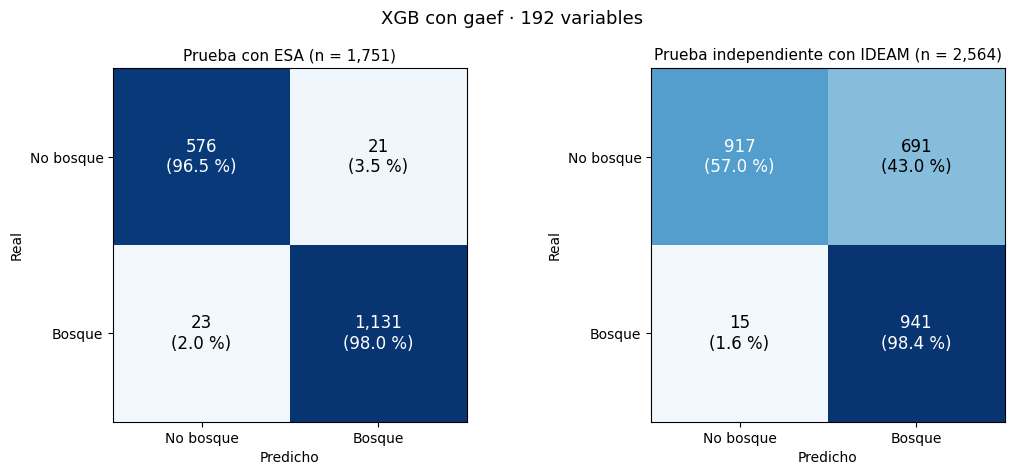

In [ ]:
# ── 7B.3 Mejores modelos: matriz de confusión (gráfica) y guardado ──
import os, json, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

ETIQ = ['No bosque', 'Bosque']

def dibuja(ax, real, pred, titulo):
    cm = confusion_matrix(real.astype(int), pred.astype(int), labels=[0, 1])
    pct = cm / cm.sum(axis=1, keepdims=True) * 100                  # % por fila
    ax.imshow(pct, cmap='Blues', vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:,}\n({pct[i, j]:.1f} %)', ha='center', va='center',
                    color='white' if pct[i, j] > 50 else 'black', fontsize=12)
    ax.set_xticks([0, 1]); ax.set_xticklabels(ETIQ); ax.set_yticks([0, 1]); ax.set_yticklabels(ETIQ)
    ax.set_xlabel('Predicho'); ax.set_ylabel('Real'); ax.set_title(titulo, fontsize=11)
    return cm

mejores = res.sort_values('prueba_F1_bosque', ascending=False).groupby('fuente').head(1)
print(f'Mejor en general por F1 de Bosque en prueba: {res.iloc[0].algoritmo.upper()} con {res.iloc[0].fuente}\n')

for _, mejor in mejores.iterrows():
    m, feats = modelos[(mejor.fuente, mejor.algoritmo)]
    d = tabla.dropna(subset=feats)
    te, ide = d[d.conjunto == 'prueba'], d[d.es_ideam]

    fig, axs = plt.subplots(1, 2 if len(ide) else 1, figsize=(11 if len(ide) else 5.5, 4.8))
    axs = np.atleast_1d(axs)
    dibuja(axs[0], te.y, m.predict(te[feats].values), f'Prueba con ESA (n = {len(te):,})')
    if len(ide):
        dibuja(axs[1], ide.ideam, m.predict(ide[feats].values), f'Prueba independiente con IDEAM (n = {len(ide):,})')
    fig.suptitle(f'{mejor.algoritmo.upper()} con {mejor.fuente} · {len(feats)} variables', fontsize=13)
    plt.tight_layout()

    if GUARDAR_MEJOR:
        nombre = f'{mejor.algoritmo}_binario_{mejor.fuente}_{"-".join(ETIQUETAS_ENTRENAMIENTO)}_{SPLIT}'
        os.makedirs(f'{MOD_P}/{nombre}', exist_ok=True)
        joblib.dump({'modelo': m, 'features': feats, 'clases': {0: 'No bosque', 1: 'Bosque'}}, f'{MOD_P}/{nombre}/modelo.joblib')
        json.dump({'metricas': json.loads(mejor.to_json()), 'etiquetas_entrenamiento': ETIQUETAS_ENTRENAMIENTO, 'combinar': COMBINAR,
                   'split': SPLIT, 'years_emb': YEARS_EMB, 'vecindario': VEC_P, 'hp': HP_P[mejor.algoritmo]},
                  open(f'{MOD_P}/{nombre}/desempeno.json', 'w'), ensure_ascii=False, indent=2)
        fig.savefig(f'{MOD_P}/{nombre}/matriz_confusion.png', dpi=150)
        print('   guardado en', f'{MOD_P}/{nombre}')
    plt.show()

## 7B.3b Matriz de confusión por año
**Qué hace:** dibuja la matriz de confusión del mejor modelo año por año: 2017–2019 contra IDEAM (prueba independiente) y 2020–2021 contra ESA (prueba). Debajo imprime una tabla con exactitud, precisión, sensibilidad y F1 de Bosque de cada año.
**Para qué sirve:** ver si el desempeño es estable en el tiempo, algo importante para detectar deforestación, donde un modelo que cambia de un año a otro produce cambios falsos.
**Cuidado al interpretar:** son los mismos puntos vistos en años distintos, así que los paneles no son pruebas independientes entre sí. Además, 2018 viene de un producto de IDEAM distinto (de cambio), y la fuente de referencia cambia de IDEAM a ESA entre 2019 y 2020.

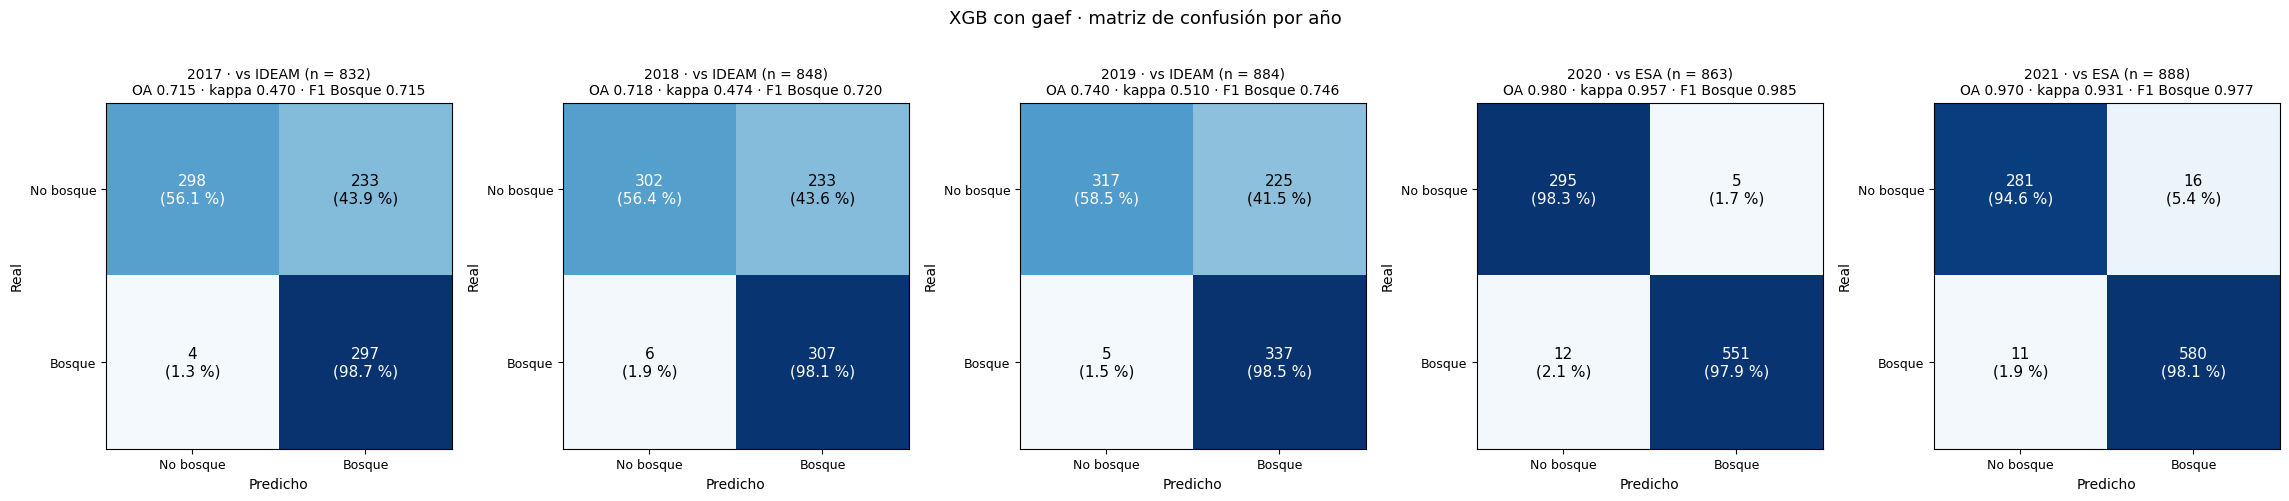

,año,referencia,n,OA,kappa,F1_macro,prec_bosque,rec_bosque,F1_bosque
0,2017,IDEAM,832,0.715,0.470,0.715,0.560,0.987,0.715
1,2018,IDEAM,848,0.718,0.474,0.718,0.569,0.981,0.720
2,2019,IDEAM,884,0.740,0.510,0.740,0.600,0.985,0.746
3,2020,ESA,863,0.980,0.957,0.978,0.991,0.979,0.985
4,2021,ESA,888,0.970,0.931,0.966,0.973,0.981,0.977


In [ ]:
# ── 7B.3b Matriz de confusión por año (mejor modelo) con OA, kappa y F1 ──
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, accuracy_score, cohen_kappa_score,
                             precision_score, recall_score, f1_score)

MODELO_VIS = ('gaef', 'xgb')                       # (fuente, algoritmo) a visualizar
ETIQ = ['No bosque', 'Bosque']

def dibuja(ax, real, pred, titulo):
    cm = confusion_matrix(real.astype(int), pred.astype(int), labels=[0, 1])
    pct = cm / cm.sum(axis=1, keepdims=True) * 100                  # % por fila
    ax.imshow(pct, cmap='Blues', vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:,}\n({pct[i, j]:.1f} %)', ha='center', va='center',
                    color='white' if pct[i, j] > 50 else 'black', fontsize=11)
    ax.set_xticks([0, 1]); ax.set_xticklabels(ETIQ, fontsize=9); ax.set_yticks([0, 1]); ax.set_yticklabels(ETIQ, fontsize=9)
    ax.set_xlabel('Predicho'); ax.set_ylabel('Real'); ax.set_title(titulo, fontsize=10)

m, feats = modelos[MODELO_VIS]
d = tabla.dropna(subset=feats)
te, ide = d[d.conjunto == 'prueba'], d[d.es_ideam]

# 2017–2019 contra IDEAM, 2020–2021 contra ESA
casos = ([('IDEAM', a, ide[ide.year == a], 'ideam') for a in sorted(ide.year.unique())] +
         [('ESA',   a, te[te.year == a],   'y')     for a in sorted(te.year.unique())])

fig, axs = plt.subplots(1, len(casos), figsize=(4.6 * len(casos), 5.2))
axs = np.atleast_1d(axs)
filas = []
for ax, (fuente_ref, a, df_a, col) in zip(axs, casos):
    pred = m.predict(df_a[feats].values)
    real = df_a[col].astype(int).values
    oa, kappa = accuracy_score(real, pred), cohen_kappa_score(real, pred)
    f1b = f1_score(real, pred, pos_label=1, zero_division=0)
    dibuja(ax, real, pred,
           f'{a} · vs {fuente_ref} (n = {len(df_a):,})\nOA {oa:.3f} · kappa {kappa:.3f} · F1 Bosque {f1b:.3f}')
    filas.append(dict(año=a, referencia=fuente_ref, n=len(df_a), OA=oa, kappa=kappa,
                      F1_macro=f1_score(real, pred, average='macro'),
                      prec_bosque=precision_score(real, pred, pos_label=1, zero_division=0),
                      rec_bosque=recall_score(real, pred, pos_label=1, zero_division=0),
                      F1_bosque=f1b))
fig.suptitle(f'{MODELO_VIS[1].upper()} con {MODELO_VIS[0]} · matriz de confusión por año', fontsize=13)
plt.tight_layout()

nombre = f'{MODELO_VIS[1]}_binario_{MODELO_VIS[0]}_{"-".join(ETIQUETAS_ENTRENAMIENTO)}_{SPLIT}'
if os.path.isdir(f'{MOD_P}/{nombre}'):
    fig.savefig(f'{MOD_P}/{nombre}/matriz_confusion_por_anio.png', dpi=150)
plt.show()

tabla_anio = pd.DataFrame(filas).round(3)
display(tabla_anio)
tabla_anio.to_csv(f'{OUT_P}/metricas_por_anio.csv', index=False)         # queda guardada para la tesis

In [ ]:
# ── 7B.3c Parpadeo en puntos con consenso estable (bloques de prueba) ──
m, feats = modelos[('gaef', 'xgb')]
d = tabla.dropna(subset=feats)
sub = d[es_test.loc[d.index]].copy()                       # solo bloques de prueba
sub['pred'] = m.predict(sub[feats].values)

P = sub.pivot(index='pid', columns='year', values='pred').dropna()        # puntos con predicción en los 5 años
E = sub.pivot(index='pid', columns='year', values='esa').reindex(P.index)
I = sub.pivot(index='pid', columns='year', values='ideam').reindex(P.index)

cambia = P.nunique(axis=1) > 1                                            # ¿la predicción no es constante?
bosque_estable   = E[[2020, 2021]].eq(1).all(axis=1) & I[[2017, 2018, 2019]].eq(1).all(axis=1)
nobosque_estable = E[[2020, 2021]].eq(0).all(axis=1) & I[[2017, 2018, 2019]].eq(0).all(axis=1)

for nombre, mask in [('Todos los puntos', slice(None)), ('Bosque estable (ESA e IDEAM)', bosque_estable),
                     ('No bosque estable (ESA e IDEAM)', nobosque_estable)]:
    c = cambia[mask]
    print(f'{nombre:35s} n = {len(c):5d} · cambian de predicción: {c.sum():4d} ({c.mean() * 100:.1f} %)')

Todos los puntos                    n =   888 · cambian de predicción:   58 (6.5 %)
Bosque estable (ESA e IDEAM)        n =   278 · cambian de predicción:    5 (1.8 %)
No bosque estable (ESA e IDEAM)     n =   276 · cambian de predicción:   18 (6.5 %)


In [ ]:
print(P[nobosque_estable].mean().round(3))      # fracción predicha como bosque, por año (puntos de no bosque estable)

year
2017    0.047
2018    0.029
2019    0.007
2020    0.004
2021    0.025
dtype: float64


# 8 Descargar Embeddings

**Qué hace:** (Felipe) lanza en Earth Engine la exportación a Drive de los embeddings anuales de AlphaEarth (64 bandas, 10 m) para todo el Huila. Si el año ya tiene su `.tif`, lo salta (los 9 años ya están).

**Qué cambió:** solo el proyecto de Earth Engine.

**Cómo funciona el código, por partes:** define años y bandas, recorta la colección anual al Huila, y por cada año faltante lanza la tarea de exportación.

In [ ]:
import ee
import geopandas as gpd
import os

ee.Authenticate()
ee.Initialize(project=GEE_PROJECT)

# ==================== PANEL DE CONTROL ====================
YEARS  = []   # [] = todos (2017–2025); ej. [1,2,3] = 2017,2018,2019
BANDS  = []   # [] = todas (A00–A63);   ej. [1,2,3] = A00,A01,A02
SCALE  = 10
# ============================================================

AÑOS_DISPONIBLES   = list(range(2017, 2026))            # índice 1 → 2017 ... 9 → 2025
BANDAS_DISPONIBLES = [f'A{i:02d}' for i in range(64)]    # índice 1 → A00 ... 64 → A63

years = [AÑOS_DISPONIBLES[i-1] for i in YEARS] if YEARS else AÑOS_DISPONIBLES
bands = [BANDAS_DISPONIBLES[i-1] for i in BANDS] if BANDS else BANDAS_DISPONIBLES

ROOT = '/content/drive/MyDrive/Cursos/Cuso Aplicaciones SIG UManizales 2026'
aoi = gpd.read_file(f'{ROOT}/datos/paulina/AOI_Huila/AOI_Huila.shp').to_crs('EPSG:4326')
region = ee.Geometry(aoi.union_all().__geo_interface__)

coll = ee.ImageCollection('GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL')
bands_tag = '-'.join(bands) if len(bands) <= 3 else f'{len(bands)}bandas'

tasks = []
for year in sorted(years):  # 2017 primero, hasta 2025
    OUT_DIR = f'{ROOT}/datos/embeddings/{year}'
    file_name = f'embedding_{bands_tag}_{year}_{SCALE}m'
    final_path = f'{OUT_DIR}/{file_name}.tif'

    if os.path.exists(final_path):
        print(f'⏭  {year}: ya existe, se salta')
        continue

    img = (coll.filterDate(f'{year}-01-01', f'{year+1}-01-01')
               .mosaic().select(bands).clip(region))

    task = ee.batch.Export.image.toDrive(
        image=img,
        description=file_name,
        folder=f'GEE_export_{year}',   # carpeta plana temporal por año
        fileNamePrefix=file_name,
        region=region,
        scale=SCALE,
        crs='EPSG:4326',
        maxPixels=1e13
    )
    task.start()
    tasks.append((year, file_name, task))
    print(f'▶ Lanzado 2017→2025 en orden: {year} ({file_name})')

print(f'\n{len(tasks)} tareas encoladas (orden: {[y for y,_,_ in tasks]}). '
      f'Monitorea en https://code.earthengine.google.com/tasks')

# 9 Inferencia departamental (modelo binario)
**Qué hace:** (código de Felipe, adaptado) aplica el modelo binario guardado en el paso 7.3 a los embeddings de AlphaEarth de todo el Huila, tesela por tesela y año por año, y guarda un `.tif` por tesela donde `1` = bosque, `0` = no bosque y `-1` = sin dato.

**Qué cambia respecto al de Felipe:** busca el modelo entre los guardados en `modelos_paulina` (por defecto, el modelo binario con AlphaEarth más reciente) y escribe en `modelos_paulina/inferencias/<año>/<modelo>/`. Solo sirve con modelos de AlphaEarth, porque Tessera no está en Drive.

**Qué produce:** `tesela_001.tif` … por año. Es la celda más larga del cuaderno (cerca de 38 teselas por año). Por defecto procesa solo 2020 y 2021; cambia `AÑOS_INFERENCIA` en el panel. Si se corta, al volver a correrla salta las teselas que ya existen.

**Cómo funciona el código, por partes:**
- **Modelo:** busca la carpeta del modelo, lo carga y deduce qué bandas y qué variables de vecindario necesita.
- **Teselas:** por año, lista los `.tif` de embeddings que tocan el Huila.
- **Lectura:** lee solo las bandas necesarias de cada tesela (si `ESCALA_M` > 10, promediando píxeles).
- **Vecindario:** calcula la media y la desviación estándar en ventana (filtro uniforme) para igualar las variables del entrenamiento.
- **Predicción:** predice solo los píxeles con dato y escribe el `.tif` de forma atómica (primero un archivo temporal), para no dejar archivos corruptos si se corta.

In [ ]:
# 9. Inferencia departamental (modelo binario) — versión por franjas (no agota la RAM)
import os, glob, json, joblib, numpy as np, rasterio, geopandas as gpd
from rasterio.windows import Window
from rasterio.enums import Resampling
from scipy.ndimage import uniform_filter
from shapely.geometry import box

FRANJA_FILAS = 256                      # filas de salida por franja; si aún falta RAM, bájalo a 128
VENTANA_PX   = VEC_P or 7
k = ESCALA_M / 10                       # 10 m -> k=1

# --- modelo
patron = f"{MOD_P}/{ALGORITMO_INFERENCIA or '*'}_binario_gaef_*/modelo.joblib"
cands = sorted(glob.glob(patron), key=os.path.getmtime)
assert cands, f"No hay modelo en {patron}"
ruta_modelo = cands[-1]
NOMBRE_MODELO = os.path.basename(os.path.dirname(ruta_modelo))
b = joblib.load(ruta_modelo); modelo, feats = b['modelo'], b['features']
bases = sorted({c.split('_')[0] for c in feats})            # p. ej. A00..A63
necesita_vec = any(c.endswith(('_mean', '_sd')) for c in feats)
idx_bd = [int(x[1:]) + 1 for x in bases]                    # banda del tif = número + 1
if hasattr(modelo, 'n_jobs'): modelo.n_jobs = 1
print('Modelo:', NOMBRE_MODELO, '| variables:', len(feats), '| bandas leídas:', len(bases))

aoi = gpd.read_file(f'{RUTA}/AOI_Huila/AOI_Huila.shp')

def predice_franja(arr, c0, c1, lote=500_000):
    idx = {n: i for i, n in enumerate(bases)}
    nod = np.isnan(arr).all(0) | (arr == 0).all(0)
    arr[:, nod] = np.nan; ok = ~nod
    if necesita_vec:
        w = VENTANA_PX
        cnt = uniform_filter(ok.astype('float32'), w, mode='nearest')
        a_ = np.where(ok, arr, 0).astype('float32')
        sm = uniform_filter(a_, size=(1, w, w), mode='nearest')
        s2 = uniform_filter(a_ * a_, size=(1, w, w), mode='nearest'); del a_
        c = np.maximum(cnt, 1e-9)
        media = sm / c; del sm
        sd = np.sqrt(np.maximum(s2 / c - media * media, 0)); del s2
    H, W = c1 - c0, arr.shape[2]
    valido = ok[c0:c1].ravel(); pred = np.full(H * W, -1, dtype='int8'); nv = int(valido.sum())
    if nv:
        X = np.empty((nv, len(feats)), dtype='float32')
        for j, nombre in enumerate(feats):
            i = idx[nombre.split('_')[0]]
            capa = media[i] if nombre.endswith('_mean') else sd[i] if nombre.endswith('_sd') else arr[i]
            X[:, j] = capa[c0:c1].ravel()[valido]
        sal = np.empty(nv, dtype='int8')
        for q in range(0, nv, lote):
            sal[q:q + lote] = modelo.predict(X[q:q + lote]).astype('int8')
        pred[valido] = sal
    return pred.reshape(H, W)

anios = AÑOS_INFERENCIA
for año in anios:
    tifs = sorted(glob.glob(f'{EMB_DIR}/{año}/*.tif'))
    assert tifs, f'No hay teselas en {EMB_DIR}/{año}'
    out_dir = f'{MOD_P}/inferencias/{año}/{NOMBRE_MODELO}'; os.makedirs(out_dir, exist_ok=True)
    # teselas que tocan el Huila, numeradas 1..N SOLO entre ellas
    sel = []
    for t in tifs:
        with rasterio.open(t) as s:
            a = aoi.to_crs(s.crs)
            if a.intersects(box(*s.bounds)).any(): sel.append(t)
    sel = list(enumerate(sel, 1))
    numeros = [n for n, _ in sel] if TESELAS in ('todas', None) else [n for n, _ in sel if n in TESELAS]
    print(f'Año {año}: {len(sel)} teselas sobre el Huila; se procesan {len(numeros)} -> {numeros}')
    for i, t in sel:
        if i not in numeros: continue
        out = f'{out_dir}/tesela_{i:03d}.tif'
        if os.path.exists(out) and not REHACER_INFERENCIA:
            print(f'  tesela {i:03d} ya existe, se omite'); continue
        with rasterio.open(t) as s:
            H, W = int(s.height / k), int(s.width / k); sy, sx = s.height / H, s.width / W
            tr = s.transform * s.transform.scale(sx, sy)
            prof = dict(driver='GTiff', height=H, width=W, count=1, dtype='int8', crs=s.crs,
                        transform=tr, nodata=-1, compress='lzw', tiled=True)
            tmp = out + '.tmp'; halo = VENTANA_PX // 2
            with rasterio.open(tmp, 'w', **prof) as dst:
                for o0 in range(0, H, FRANJA_FILAS):
                    o1 = min(o0 + FRANJA_FILAS, H); a0 = max(o0 - halo, 0); a1 = min(o1 + halo, H)
                    win = Window(0, a0 * sy, s.width, (a1 - a0) * sy)
                    arr = s.read(idx_bd, window=win, out_shape=(len(idx_bd), a1 - a0, W),
                                 resampling=Resampling.average).astype('float32')
                    p = predice_franja(arr, o0 - a0, o0 - a0 + (o1 - o0))
                    dst.write(p, 1, window=Window(0, o0, W, o1 - o0))
                    del arr, p
            os.replace(tmp, out)
        print(f'  tesela {i:03d} lista -> {out}')
print('Inferencia terminada.')

Modelo: xgb_binario_gaef_esa_bloques | variables: 192 | bandas leídas: 64
Año 2020: 38 teselas sobre el Huila; se procesan 38 -> [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38]
  tesela 001 ya existe, se omite
  tesela 002 ya existe, se omite
  tesela 003 ya existe, se omite
  tesela 004 ya existe, se omite
  tesela 005 ya existe, se omite
  tesela 006 ya existe, se omite
  tesela 007 ya existe, se omite
  tesela 008 ya existe, se omite
  tesela 009 ya existe, se omite
  tesela 010 lista -> /content/drive/MyDrive/APLICACIONES SIG/modelos_paulina/inferencias/2020/xgb_binario_gaef_esa_bloques/tesela_010.tif
  tesela 011 lista -> /content/drive/MyDrive/APLICACIONES SIG/modelos_paulina/inferencias/2020/xgb_binario_gaef_esa_bloques/tesela_011.tif
  tesela 012 lista -> /content/drive/MyDrive/APLICACIONES SIG/modelos_paulina/inferencias/2020/xgb_binario_gaef_esa_bloques/tesela_012.tif
  tesela 013 

In [ ]:
# 9b. Revisión de la inferencia 2020
# Cuenta píxeles de bosque / no bosque / sin dato en las 38 teselas. No guarda nada.
import glob, rasterio, numpy as np

AÑO_REVISION = 2020                      # cambiar a 2021 cuando se revise ese año

rutas = sorted(glob.glob(f'{MOD_P}/inferencias/{AÑO_REVISION}/{NOMBRE_MODELO}/tesela_*.tif'))
tot = {1: 0, 0: 0, -1: 0}
for r in rutas:
    with rasterio.open(r) as s:
        a = s.read(1)
    v, c = np.unique(a, return_counts=True)
    for x, n in zip(v, c):
        tot[int(x)] += int(n)

t = sum(tot.values())
print(len(rutas), 'teselas')
for k, nombre in [(1, 'Bosque'), (0, 'No bosque'), (-1, 'Sin dato')]:
    print(f'{nombre}: {tot[k]:,}  ({100*tot[k]/t:.1f}%)')

38 teselas
Bosque: 110,964,112  (33.0%)
No bosque: 71,788,025  (21.4%)
Sin dato: 153,392,247  (45.6%)


In [ ]:
# 9c. Comparación departamental 2020: modelo vs ESA 2020 vs IDEAM 2019
# Pone las tres fuentes en una misma cuadrícula de ~100 m sobre el Huila y compara % de bosque y acuerdo. No guarda mapas.
import glob, os, numpy as np, pandas as pd, rasterio, geopandas as gpd
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from rasterio.features import rasterize
from rasterio.transform import from_origin

AÑO_MODELO = 2020
AÑO_IDEAM  = 2019                         # IDEAM no tiene 2020; se usa el más cercano
RES = 0.0009                              # grados (~100 m)
IDEAM_DIR = f'{ROOT}/DATOS/INVENTARIO FORESTAL'
ESA_VALIDAS = [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100]

# --- cuadrícula común sobre el Huila (EPSG:4326) y máscara del departamento
aoi = gpd.read_file(f'{RUTA}/AOI_Huila/AOI_Huila.shp').to_crs(4326)
w_, s_, e_, n_ = aoi.total_bounds
W, H = int(np.ceil((e_ - w_) / RES)), int(np.ceil((n_ - s_) / RES))
tr = from_origin(w_, n_, RES, RES)
dentro = rasterize([(g, 1) for g in aoi.geometry], out_shape=(H, W), transform=tr, fill=0, dtype='uint8').astype(bool)
km2_celda = (RES * 111.32) ** 2 * np.cos(np.radians((n_ + s_) / 2))
print(f'Cuadrícula {H}×{W}; celdas dentro del Huila: {dentro.sum():,} (~{dentro.sum()*km2_celda:,.0f} km²)')

def a_cuadricula(ruta, nodata):
    with rasterio.open(ruta) as src:
        with WarpedVRT(src, crs='EPSG:4326', transform=tr, width=W, height=H,
                       resampling=Resampling.nearest, nodata=nodata) as v:
            return v.read(1)

# --- modelo 2020: mosaico de las teselas
mod = np.full((H, W), -1, dtype='int8')
rutas = sorted(glob.glob(f'{MOD_P}/inferencias/{AÑO_MODELO}/{NOMBRE_MODELO}/tesela_*.tif'))
assert rutas, 'No hay teselas del modelo'
for r in rutas:
    a = a_cuadricula(r, -1)
    ok = (a == 0) | (a == 1)
    mod[ok] = a[ok]
print('Teselas del modelo:', len(rutas))

# --- ESA 2020 (Tree=10 -> bosque) e IDEAM (1 bosque, 2 no bosque)
esa_raw = a_cuadricula(ESA_TIF.format(2020), 0)
esa = np.where(np.isin(esa_raw, ESA_VALIDAS), (esa_raw == 10).astype('int8'), -1).astype('int8')
nombre_ideam = IDEAM[AÑO_IDEAM][0]
hall = glob.glob(f'{IDEAM_DIR}/**/{nombre_ideam}', recursive=True)
assert hall, f'No encontré {nombre_ideam} bajo {IDEAM_DIR}'
ide_raw = a_cuadricula(hall[0], 0)
ide = np.where(np.isin(ide_raw, [1, 2]), (ide_raw == 1).astype('int8'), -1).astype('int8')
del esa_raw, ide_raw

# --- % de bosque de cada fuente (solo celdas con dato dentro del Huila)
filas = []
for nombre, m in [(f'Modelo {AÑO_MODELO}', mod), ('ESA 2020', esa), (f'IDEAM {AÑO_IDEAM}', ide)]:
    v = dentro & (m >= 0)
    filas.append({'fuente': nombre, 'celdas_con_dato': int(v.sum()),
                  'bosque_%': round(100 * (m[v] == 1).mean(), 1),
                  'bosque_km2': round(float((m[v] == 1).sum()) * km2_celda)})
print(pd.DataFrame(filas).to_string(index=False))

# --- acuerdo celda a celda (referencia = ESA o IDEAM)
for nombre, ref in [('ESA 2020', esa), (f'IDEAM {AÑO_IDEAM}', ide)]:
    v = dentro & (mod >= 0) & (ref >= 0)
    p, r = mod[v], ref[v]
    tp = int(((p == 1) & (r == 1)).sum()); fp = int(((p == 1) & (r == 0)).sum())
    fn = int(((p == 0) & (r == 1)).sum()); tn = int(((p == 0) & (r == 0)).sum())
    n = tp + fp + fn + tn
    print(f'\nModelo vs {nombre}: celdas={n:,}  aciertos(OA)={100*(tp+tn)/n:.1f}%  '
          f'precisión bosque={tp/max(tp+fp,1):.2f}  sensibilidad bosque={tp/max(tp+fn,1):.2f}')
    print(f'  bosque→bosque {100*tp/n:.1f}% | modelo bosque / ref no bosque {100*fp/n:.1f}% | '
          f'modelo no bosque / ref bosque {100*fn/n:.1f}% | no bosque→no bosque {100*tn/n:.1f}%')

Cuadrícula 2546×2458; celdas dentro del Huila: 1,820,000 (~18,248 km²)
Teselas del modelo: 38
     fuente  celdas_con_dato  bosque_%  bosque_km2
Modelo 2020          1767247      61.0       10813
   ESA 2020          1671912      57.4        9616
 IDEAM 2019          1813478      28.9        5252

Modelo vs ESA 2020: celdas=1,637,988  aciertos(OA)=88.0%  precisión bosque=0.86  sensibilidad bosque=0.94
  bosque→bosque 53.7% | modelo bosque / ref no bosque 8.6% | modelo no bosque / ref bosque 3.3% | no bosque→no bosque 34.3%

Modelo vs IDEAM 2019: celdas=1,760,832  aciertos(OA)=67.4%  precisión bosque=0.47  sensibilidad bosque=0.98
  bosque→bosque 28.7% | modelo bosque / ref no bosque 32.2% | modelo no bosque / ref bosque 0.5% | no bosque→no bosque 38.6%


# 10 Eliminar hidrografía y cuerpos de agua
**Qué hace:** (código de Felipe, adaptado) en las teselas de la inferencia convierte en "sin dato" (`-1`) los píxeles de agua, para que el agua no se cuente como no bosque. Usa la hidrografía vectorial (drenaje doble, drenaje sencillo y embalse) y, además, la probabilidad anual de agua de Dynamic World.

**Qué cambia respecto al de Felipe:** trabaja sobre `modelos_paulina/inferencias` y toma los parámetros del panel (`AÑOS_MASCARA`, `BUFFER_M`, `USAR_DW`, `PROB_MIN`, etc.). Marca cada tesela ya enmascarada para no repetirla, y guarda un registro en `_log_mascara_agua.csv`.

**Cómo funciona el código, por partes:**
- **Hidrografía:** carga las tres capas vectoriales una sola vez y las reproyecta según el sistema de coordenadas de cada tesela.
- **Agua de Dynamic World:** por año calcula la probabilidad media de agua y la binariza (`PROB_MIN`); la pide a Earth Engine por teselas, con reintentos.
- **Máscara:** combina el agua vectorial y la de Dynamic World y pone `-1` en esos píxeles.
- **Escritura:** guarda la tesela de forma atómica, la marca como enmascarada y añade una fila al registro con las hectáreas borradas.

In [ ]:
# 10. Eliminar hidrografía y cuerpos de agua (máscara de agua sobre las inferencias)
# Borra (pone sin dato) los píxeles de ríos, embalses y agua de Dynamic World en cada tesela.
# Antes de modificar cada tesela guarda una copia en modelos_paulina/inferencias_sin_mascara/.
AÑOS, MODELOS, REHACER = AÑOS_MASCARA, 'todos', REHACER_MASCARA
CAPAS   = [f'{RUTA}/DRENAJE_DOBLE/drenaje_doble.shp',
           f'{RUTA}/DRENAJE_SENCILLO/drenaje_sencillo.shp',
           f'{RUTA}/EMBALSE/embalse.shp']
AOI     = f'{RUTA}/AOI_Huila/AOI_Huila.shp'
INF_DIR = f'{MOD_P}/inferencias'
LOG     = f'{INF_DIR}/_log_mascara_agua.csv'
RESP    = f'{MOD_P}/inferencias_sin_mascara'   # copia de seguridad de las teselas originales

import shutil, ee, glob, os, time, numpy as np, pandas as pd, geopandas as gpd, rasterio
from rasterio.features import rasterize
from shapely.geometry import box

# ── Hidrografía vectorial (una sola vez) ──
hidro = pd.concat([gpd.read_file(c).to_crs(9377)[['geometry']] for c in CAPAS], ignore_index=True)
hidro = hidro[hidro.geometry.notna() & ~hidro.geometry.is_empty].reset_index(drop=True)
if BUFFER_M: hidro['geometry'] = hidro.buffer(BUFFER_M)
cache = {}
print(f'Hidrografía vectorial: {len(hidro):,} geometrías')

# ── GEE ──
if USAR_DW:
    try: ee.Initialize(project=GEE_PROJECT)
    except Exception: ee.Authenticate(); ee.Initialize(project=GEE_PROJECT)
    reg = ee.Geometry.Rectangle(list(gpd.read_file(AOI).to_crs(4326).total_bounds))
    pend = ee.Terrain.slope(ee.Image('USGS/SRTMGL1_003')) if PEND_MAX is not None else None
    def agua_dw(y):
        a = (ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1').filterDate(f'{y}-01-01', f'{y+1}-01-01')
             .filterBounds(reg).select('water').mean().gte(PROB_MIN))
        if pend is not None: a = a.And(pend.lte(PEND_MAX))
        return a.unmask(0).rename('agua').toUint8()
    def pixeles(img, tr, crs, H, W):
        grid = {'dimensions': {'width': W, 'height': H}, 'crsCode': crs.to_string(),
                'affineTransform': dict(scaleX=tr.a, shearX=tr.b, translateX=tr.c, shearY=tr.d, scaleY=tr.e, translateY=tr.f)}
        for k in range(REINTENTOS):
            try: return ee.data.computePixels({'expression': img, 'fileFormat': 'NUMPY_NDARRAY', 'grid': grid})['agua'].astype(bool)
            except Exception as e:
                if k == REINTENTOS - 1: raise
                print(f'    GEE falló ({e.__class__.__name__}), reintento {k+1} en {20*(k+1)} s'); time.sleep(20 * (k + 1))

años_disp = sorted(int(os.path.basename(d)) for d in glob.glob(f'{INF_DIR}/*') if os.path.basename(d).isdigit())
años = años_disp if AÑOS == 'todas' else ([AÑOS] if isinstance(AÑOS, int) else list(AÑOS))

for año in años:
    img = agua_dw(año) if USAR_DW else None
    hechas = saltadas = fallidas = 0
    for mdir in sorted(glob.glob(f'{INF_DIR}/{año}/*/')):
        if MODELOS != 'todos' and os.path.basename(mdir.rstrip('/')) != MODELOS: continue
        for f in sorted(glob.glob(f'{mdir}tesela_*.tif')):
            with rasterio.open(f) as s:
                if s.tags().get('HIDRO_MASK') == '1' and not REHACER: saltadas += 1; continue
                a, prof, tags = s.read(1), s.profile, s.tags()
                tr, crs, bnds = s.transform, s.crs, s.bounds
                nd = s.nodata if s.nodata is not None else -1
            H, W = a.shape
            # vectorial
            k = crs.to_string()
            if k not in cache: cache[k] = hidro.to_crs(crs)
            sub = cache[k].iloc[cache[k].sindex.query(box(*bnds))]
            mv = rasterize(sub.geometry, out_shape=(H, W), transform=tr, fill=0, default_value=1,
                           all_touched=ALL_TOUCHED, dtype='uint8').astype(bool) if len(sub) else np.zeros((H, W), bool)
            # Dynamic World
            try: mj = pixeles(img, tr, crs, H, W) if USAR_DW else np.zeros((H, W), bool)
            except Exception as e:
                print(f'  ✗ {os.path.basename(f)}: GEE no respondió ({e}); se reintentará en la próxima ejecución')
                fallidas += 1; continue
            val = a != nd
            n_v, n_dw = int((mv & val).sum()), int((mj & ~mv & val).sum())
            a[mv | mj] = nd
            # copia de seguridad (solo la primera vez: guarda la tesela original sin máscara)
            bk = f'{RESP}/{año}/{os.path.basename(mdir.rstrip("/"))}/{os.path.basename(f)}'
            if not os.path.exists(bk):
                os.makedirs(os.path.dirname(bk), exist_ok=True); shutil.copy2(f, bk)
            # escritura atómica
            for c in ('blockxsize', 'blockysize', 'tiled'): prof.pop(c, None)
            prof.update(compress='lzw', nodata=nd)
            with rasterio.open(f + '.tmp', 'w', **prof) as d:
                d.write(a, 1)
                d.update_tags(**tags, HIDRO_MASK='1', HIDRO_BUFFER_M=str(BUFFER_M),
                              DW_PROB_MIN=str(PROB_MIN if USAR_DW else 'na'), DW_PEND_MAX=str(PEND_MAX))
            os.replace(f + '.tmp', f)
            if os.path.exists(f + '.aux.xml'): os.remove(f + '.aux.xml')
            pd.DataFrame([dict(año=año, modelo=os.path.basename(mdir.rstrip('/')), tesela=os.path.basename(f),
                               px_vectorial=n_v, px_dynamicworld=n_dw, ha_total=(n_v + n_dw) / 100)]
                         ).to_csv(LOG, mode='a', header=not os.path.exists(LOG), index=False)
            hechas += 1
            print(f'  {año} · {os.path.basename(f)}: vectorial {n_v/100:,.1f} ha · DW {n_dw/100:,.1f} ha')
    print(f'✓ {año}: {hechas} enmascaradas · {saltadas} ya estaban · {fallidas} fallidas\n')

if os.path.exists(LOG):
    print('Resumen (ha borradas por año):\n', pd.read_csv(LOG).groupby('año')[['ha_total']].sum().round(1))

/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received an unexpected geometry.  Either a polygon with interior rings, or a polygon with less than 4 points, or a non-Polygon geometry.  Return arguments as a collection.
  return ogr_read(
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: Geometry of polygon of fid 11 cannot be translated to Simple Geometry. All polygons will be contained in a multipolygon.
  return ogr_read(


Hidrografía vectorial: 10,921 geometrías
  2020 · tesela_001.tif: vectorial 125.3 ha · DW 0.0 ha
  2020 · tesela_002.tif: vectorial 1,075.7 ha · DW 4.3 ha
  2020 · tesela_003.tif: vectorial 0.3 ha · DW 0.0 ha
  2020 · tesela_004.tif: vectorial 1.5 ha · DW 0.0 ha
  2020 · tesela_005.tif: vectorial 424.1 ha · DW 2.8 ha
  2020 · tesela_006.tif: vectorial 1,364.4 ha · DW 226.8 ha
  2020 · tesela_007.tif: vectorial 1,228.5 ha · DW 7.0 ha
  2020 · tesela_008.tif: vectorial 566.2 ha · DW 0.0 ha
  2020 · tesela_009.tif: vectorial 356.3 ha · DW 0.0 ha
  2020 · tesela_010.tif: vectorial 2,630.7 ha · DW 153.2 ha
  2020 · tesela_011.tif: vectorial 2,183.7 ha · DW 126.5 ha
  2020 · tesela_012.tif: vectorial 1,389.3 ha · DW 10.1 ha
  2020 · tesela_013.tif: vectorial 123.0 ha · DW 0.1 ha
  2020 · tesela_014.tif: vectorial 209.2 ha · DW 5.3 ha
  2020 · tesela_015.tif: vectorial 1,203.3 ha · DW 0.0 ha
  2020 · tesela_016.tif: vectorial 2,908.2 ha · DW 244.5 ha
  2020 · tesela_017.tif: vectorial 1,895.3

## Cuando tengas resultados

Aunque algo se vea raro o no funcione al 100 %, avísale al profesor: el objetivo de esta etapa es tener el flujo completo con métricas. Con las inferencias binarias por año, el siguiente paso es calcular la deforestación como bosque en el año *t* → no bosque en *t+1*, y medir cuántos píxeles "parpadean" (bosque → no bosque → bosque) para comparar el modelo binario con el de 6 clases.